# Epiphyte lysimeter: field analysis

Field version of the lab notebook. Set everything in the **Settings** cell below, then **Run All**.

Water balance per logging interval Δt (default 15 min):

$$ET = P_{epi} - D_{epi} - \frac{\Delta S_{epi}}{\Delta t}, \qquad P_{epi} = TF + F$$

- $TF$ throughfall (gauge), $F$ fog interception (FIESTA), $D_{epi}$ drainage (lysimeter tipping bucket,
  minus the throughfall that falls straight into the part of its funnel the epiphyte does not cover),
  $\Delta S_{epi}$ change in measured (temperature-corrected) mass between consecutive interval edges.
- All terms are converted from mass to water depth with the **projected area** of the epiphyte
  (1 g over 1 cm² = 10 mm) and reported as mean rates over Δt in **mm h⁻¹**. $ET$ is the residual.

Sections:
1. Overview of all logged variables
2. Weight: raw vs temperature-corrected
3. Weight with fog periods (fog flag file)
4. Weight with FIESTA fog interception and throughfall
5. Throughfall and drainage
6. Water balance closure: TF + F = ΔS + D (total, per day, per event)
7. Evapotranspiration: 15-min, per day, per event, total; mass loss in dry periods
8. Comparisons: temperature correction, input terms, fog / rain / day / night
9. Quality check: hours the balance cannot explain
10. Event types: fog / dew, evaporation, light rain, strong rain compared

A graph is only drawn when there is enough data for it (`MIN_POINTS`); otherwise the notebook prints why it was skipped.

In [1]:
# ======================================================================
#  SETTINGS: all inputs are here
# ======================================================================
from pathlib import Path

# ---- 1. Lysimeter log ----
DATA_PATH    = Path("lys2.csv")  # .csv or .xlsx (an .xlsx is also saved as .csv)
SHEET        = 0                   # only for .xlsx: sheet name or index
START        = "2026-10-16 16:38"                # analysis window, e.g. "2026-10-20 00:00"; None = from the first row
END          = None                # None = to the last row
DROP_FLAGGED = True                # drop rows where the load-cell amplifier failed (status contains "HX_")


# ---- 2. Calibration and temperature correction ----
#   weight_g = (ADC − ADC0 − ALPHA·ΔT) × SLOPE / (1 + BETA·ΔT),   ΔT = T − T_REF
ADC0        = 57922                # ADC reading of the empty lysimeter (tare)
SLOPE       = 0.011387             # grams per ADC count
T_REF       = 21                 # temperature (°C) at which ADC0 was measured
ALPHA       = 212.6                # zero drift (counts/°C), overnight regression
BETA        = 0.000867             # span drift (fraction/°C); 0 = zero correction only
CAL_T_RANGE = (18.6, 21.4)         # temperatures of the calibration sessions (warning if far outside)

# ---- 3. Epiphyte, drainage and water-balance interval ----
AREA_CM2  = 271.36                    # projected area of the epiphyte (cm²): mass -> water depth (1 g / 1 cm² = 10 mm)
DRAIN_MM_PER_TIP = 0.2             # drainage tipping bucket resolution: mm per tip over ITS OWN funnel
DRAIN_FUNNEL_CM2 = 314.16           # funnel area of the drainage bucket (cm²); 20 cm diameter = 314 cm²
                                   #   -> one tip = 0.2 mm × 314 cm² = 6.28 ml
DIRECT_CM2 = None                  # funnel area NOT covered by the epiphyte, where throughfall falls straight into the bucket
                                   #   None = DRAIN_FUNNEL_CM2 − AREA_CM2 | 0 = funnel fully covered / shielded
DIRECT_SOURCE = "TF"               # what falls into that open part: "TF" = throughfall gauge (funnel under the canopy)
                                   #   or "rain" = Tempest / open-field rain (funnel open to the sky)
DT        = "15min"                # water-balance interval Δt
DRAIN_LAG = "auto"                 # delay between water reaching the plant and the drainage tips, used in the quality check:
                                   # "auto" = lag (0–2 h) where input and drainage match best, or fixed e.g. "30min"; "0min" = off
EVENT_MIN_MM = 0.1                 # closure / ET per event: an interval is wet when TF ≥ this (mm per Δt) or FIESTA fog > 0
EVENT_GAP = "2h"                   # wet intervals closer than this belong to the same event
EVENT_TAIL = "2h"                  # closure check: time added after the last input so late drainage and dripping are included
DRY_MIN   = "2h"                   # mass loss: shortest dry period (no input, no drainage) that is evaluated
SMOOTH_N  = 1                      # readings in a centred rolling median before ΔS (1 = no smoothing)
MAX_GAP   = "20min"                # a mass at an interval edge is only used if readings exist within this distance on both sides
DAY_HOURS = (6, 18)                # day = 06:00–18:00 for the day/night split

# ---- 3b. Event types (section 10): fog / dew, evaporation, light rain, strong rain ----
STRONG_RAIN_MMH = 5             # a rain event is "strong" when its wettest hour has ≥ this throughfall (mm/h), else "light"
                                   #   (2.5 mm/h is the usual light / moderate rain boundary)
DEW_SPREAD_C    = 0.3              # fog / dew outside rain: air within this many °C of its dew point (lysimeter T/RH sensor),
                                   #   or the fog flag is on, or FIESTA fog > 0; otherwise "evaporation"
TYPE_MIN        = "1h"             # shortest fog / dew or evaporation run that counts as an event
TYPE_MIN_COVER  = 0.8              # events with complete data for less than this share of their length are left out

# ---- 4. Throughfall gauge ----
TF_PATH       = Path("loggers.csv")  # None = no throughfall file (TF = 0, with a warning)
TF_COL        = "Agroforestry_throughfall_mm"   # column with the throughfall record
TF_KIND       = "mm"               # "mm" or "tips" per record | "cum_mm" or "cum_tips" for a running total
TF_MM_PER_TIP = 0.2                # only used when TF_KIND is tips
TF_LABEL      = "end"              # timestamp marks the "end" (Mayfly, event logs) or "start" of each record
TF_SHIFT_H    = 0                  # hours to add if the gauge logger runs on another clock

# ---- 5. Fog flag file ----
FOG_PATH     = Path("loggers.csv")      # None = no fog flag file
FOG_FLAG_COL = "FOG_TEMPEST_RH"          # 1 = fog, 0 = no fog; None = first column starting with "FOG"
FOG_SHIFT_H  = 0                         # hours to add if the fog logger runs on another clock

# ---- 6. FIESTA fog interception (weather station file) ----
MET_PATH     = Path("fog_AF_15min.csv")  # None = skip (F = 0, with a warning)
FIESTA_COL   = "fiesta_fog_mm"           # modelled fog interception per interval (mm)
MET_FLAG_COL = "fog_flag"                # used for fog periods only if there is no fog flag file
RAIN_COL     = "rain_mm"                 # open-field rain, compared with throughfall; None = skip
MET_LABEL    = "start"                   # timestamp marks the "start" or "end" of each record
FOG_AREA_CM2 = 102.6                     # epiphyte area facing the fog (cm²), one side 113.443, other 91.779
EFFICIENCY   = 1.0                       # plant capture relative to the model (1 = same)
LOCAL_TZ     = "America/Guatemala"       # time zone of the lysimeter clock

# ---- 6b. Tempest weather station: open-field precipitation ----
TEMPEST_PATH       = Path("tempest.csv")   # None = skip (then RAIN_COL of the weather-station file is used, if any)
TEMPEST_PRECIP_COL = "precip"              # rain column (mm per report_interval, i.e. per minute for a Tempest)
TEMPEST_PRECIP_AGG = "auto"                # how the records were made from the 1-min reports: "mean" (averaged, e.g. a 15-min
                                           #   resample of all columns), "sum", or "auto" = mean if the records are longer than
                                           #   report_interval -> precip × (record length / report_interval)
TEMPEST_LABEL      = "start"               # "start" if the records were resampled (pandas default), "end" for raw Tempest data
TEMPEST_SHIFT_H    = 0                     # hours to add if the station runs on another clock


# ---- 7. Output and uncertainty ----
MIN_POINTS  = 8                    # minimum data points for a graph to be drawn
SAVE_PNG    = False                # save every graph next to the data file
SAVE_CSV    = True                 # save the 15-min water balance next to the data file
TIP_CAL_ERR = 0.03                 # relative uncertainty of TIP_ML
TEMP_RESID  = 0.9                  # g/°C assumed left after temperature correction
TF_REL_ERR  = 0.10                 # relative uncertainty of throughfall (gauge catch, spatial variability)
FOG_REL_ERR = 0.50                 # relative uncertainty of FIESTA fog interception (modelled)
K_SIGMA     = 2                    # intervals with |ET| beyond K_SIGMA·σ are flagged in the quality check

## Setup (no settings below this point)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
%matplotlib inline
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

COLUMNS = ["boot_session", "elapsed_sec", "timestamp", "avg_temperature_C",
           "avg_humidity_pct", "avg_raw_adc", "avg_weight_g", "total_tips", "status"]
STEP = pd.Timedelta(DT)
DT_H = STEP / pd.Timedelta(hours=1)
G2MM = 10.0 / AREA_CM2                      # mm of water per gram over the projected area
TIP_ML = DRAIN_MM_PER_TIP * 0.1 * DRAIN_FUNNEL_CM2          # ml per drainage tip (mm × cm² / 10)
DIRECT_AREA = max(DRAIN_FUNNEL_CM2 - AREA_CM2, 0.0) if DIRECT_CM2 is None else float(DIRECT_CM2)
DIRECT_FRAC = DIRECT_AREA / AREA_CM2                        # direct throughfall in the bucket, per mm of TF on the plant
EPI2FUN = AREA_CM2 / DRAIN_FUNNEL_CM2                       # mm over the epiphyte -> mm over the drainage funnel (rain-gauge mm)
MM2ML = AREA_CM2 / 10.0                                     # mm over the epiphyte -> ml


def ns(t):
    """Datetimes -> int64 nanoseconds (works for Series, Index and arrays)."""
    return np.asarray(pd.to_datetime(t)).astype("datetime64[ns]").astype("int64")


def read_table(path, sheet=0):
    path = Path(path)
    if path.suffix.lower() in (".xlsx", ".xlsm", ".xls"):
        d = pd.read_excel(path, sheet_name=sheet)
    else:
        d = pd.read_csv(path, sep=None, engine="python")
    d.columns = [str(c).strip() for c in d.columns]
    return d


def load(path, sheet=0):
    d = read_table(path, sheet)
    missing = [c for c in COLUMNS if c not in d.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}. Found: {list(d.columns)}")
    d = d[COLUMNS].copy()
    d["timestamp"] = pd.to_datetime(d["timestamp"], errors="coerce")
    for c in COLUMNS[3:8] + ["elapsed_sec"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    d["status"] = d["status"].astype(str).str.strip()
    return d.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)


def select_window(d, start=None, end=None, col="timestamp"):
    m = d[col].notna()
    if start is not None: m &= d[col] >= pd.Timestamp(start)
    if end is not None:   m &= d[col] <= pd.Timestamp(end)
    return d[m].copy()


def weight_tc(adc, temp_c):
    dT = np.asarray(temp_c, float) - T_REF
    return (np.asarray(adc, float) - ADC0 - ALPHA * dT) * SLOPE / (1 + BETA * dT)


def to_local_naive(s):
    """Parse timestamps; if they carry an offset (e.g. -06:00 or Z) or are Unix epoch seconds (Tempest),
    convert to LOCAL_TZ and drop the time zone."""
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() > 0.9 and num.median() > 1e9:
        return pd.to_datetime(num, unit="s", utc=True).dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    if s.astype(str).str.contains(r"[+-]\d\d:\d\d$|Z$", regex=True).any():
        return pd.to_datetime(s, errors="coerce", utc=True).dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    return pd.to_datetime(s, errors="coerce")


def time_col(d):
    for c in d.columns:
        if c.lower() in ("timestamp", "time", "datetime", "date_time"):
            return c
    return d.columns[0]


def to_increments(values, kind, mm_per_tip=1.0):
    """Gauge column -> mm per record. Running counters are differenced (a counter reset counts from 0)."""
    v = pd.to_numeric(values, errors="coerce").reset_index(drop=True)
    if kind.startswith("cum_"):
        inc = v.diff()
        inc = inc.where(inc >= 0, v)          # counter reset: the new value is the increment
        v = inc.fillna(0)
    if "tips" in kind:
        v = v * mm_per_tip
    return v.fillna(0)


def tip_increments(d):
    """total_tips is a running counter that restarts at 0 on every boot -> tips per reading.
    Within a boot session: difference to the previous reading. First reading of a session: its own count if it
    was taken right after boot (elapsed_sec within one logging interval), else 0 (counter started before the window).
    A counter that drops without a reboot is treated as a reset: the new value is the increment."""
    tips = d["total_tips"].astype(float)
    block = (d["boot_session"] != d["boot_session"].shift()).cumsum()     # contiguous sessions, even if ids repeat
    inc = tips.groupby(block).diff()
    inc = inc.where(~(inc < 0), tips)                                      # reset without reboot
    first = inc.isna()
    step_s = d["timestamp"].diff().median().total_seconds() if len(d) > 1 else 900
    fresh = first & (d["elapsed_sec"].fillna(np.inf) <= step_s)
    inc[fresh] = tips[fresh]
    return inc.fillna(0).clip(lower=0)


def file_ok(path, what):
    if path is None:
        print(f"⏭ {what}: no file set")
        return False
    if not Path(path).exists():
        print(f"⏭ {what}: file not found ({path})")
        return False
    return True


def enough(n, what, need=None):
    need = MIN_POINTS if need is None else need
    if n < need:
        print(f"⏭ Skipped '{what}': only {n} data point(s), need at least {need}")
        return False
    return True


def periods_from_flag(ts, flag):
    """Turn a 0/1 flag time series into a list of (start, end) periods."""
    f = pd.DataFrame({"t": ts, "on": flag}).dropna(subset=["t"]).sort_values("t").reset_index(drop=True)
    if f.empty or not f["on"].any():
        return []
    step = f["t"].diff().median()
    block = (f["on"] != f["on"].shift()).cumsum()
    return [(g["t"].iloc[0], g["t"].iloc[-1] + step) for _, g in f[f["on"]].groupby(block[f["on"]])]


def clip_periods(periods, a, b):
    return [(max(p, a), min(q, b)) for p, q in periods if q > a and p < b]


def in_periods(times, periods):
    t = pd.to_datetime(pd.Series(times)).values
    m = np.zeros(len(t), bool)
    for p, q in periods:
        m |= (t >= np.datetime64(p)) & (t < np.datetime64(q))
    return m


def shade(ax, periods, color="lightsteelblue", label="fog"):
    for j, (p, q) in enumerate(periods):
        ax.axvspan(p, q, color=color, alpha=0.35, lw=0, label=label if j == 0 else None)


def time_axis(ax):
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))


def finish(fig, name):
    if SAVE_PNG:
        out = DATA_PATH.with_name(f"{DATA_PATH.stem}_{name}.png")
        fig.savefig(out, dpi=150, bbox_inches="tight")
        print(f"Saved {out}")
    plt.show()


def add_temperature(ax, d):
    tw = ax.twinx()
    tw.plot(d["timestamp"], d["avg_temperature_C"], color="tab:red", lw=0.8, alpha=0.5, label="temperature")
    tw.set_ylabel("Temperature (°C)", color="tab:red")
    tw.grid(False)
    return tw


def add_rain(ax, offset=1.08, scale=3):
    """Rain (and throughfall) per interval as bars hanging from the top, on an extra right axis."""
    if not (HAS_RAIN or np.nansum(wb["TF_mm"]) > 0):
        return None
    ar = ax.twinx(); ar.grid(False)
    ar.spines["right"].set_position(("axes", offset))
    bw = STEP / pd.Timedelta(days=1) * 0.9
    top = 0.0
    if HAS_RAIN:
        ar.bar(wb["start"], wb["rain_mm"], width=bw, align="edge", color="tab:blue", alpha=0.35, label=f"{RAIN_NAME} per {DT}")
        top = np.nanmax(wb["rain_mm"])
    if np.nansum(wb["TF_mm"]) > 0:
        ar.step(wb["end"], wb["TF_mm"], where="pre", color="tab:purple", lw=1, label=f"throughfall per {DT}")
        top = max(top, np.nanmax(wb["TF_mm"]))
    ar.set_ylim(max(top, 0.2) * scale, 0)
    ar.set_ylabel(f"Precipitation (mm per {DT})", color="tab:blue")
    return ar


def legend_all(fig_or_ax, axes, **kw):
    h, l = [], []
    for a_ in axes:
        hh, ll = a_.get_legend_handles_labels(); h += hh; l += ll
    fig_or_ax.legend(h, l, fontsize=8, frameon=False, **kw)

## Load and prepare data

In [3]:
df = load(DATA_PATH, SHEET)
print(f"Loaded {DATA_PATH}: {len(df)} rows, {df['timestamp'].min()} → {df['timestamp'].max()}")
if DATA_PATH.suffix.lower() != ".csv":
    df.to_csv(DATA_PATH.with_suffix(".csv"), index=False)
    print(f"Saved CSV copy: {DATA_PATH.with_suffix('.csv')}")

if DROP_FLAGGED:
    bad = df["status"].str.contains("HX_") | df["avg_raw_adc"].isna()
    if bad.any():
        print(f"Dropped {bad.sum()} row(s) with a failed load-cell reading (HX_ flag or no ADC value)")
    df = df[~bad].copy()

dw = select_window(df, START, END)
if dw.empty:
    raise ValueError(f"No rows between {START} and {END}. Data covers {df['timestamp'].min()} → {df['timestamp'].max()}")
dw = dw.reset_index(drop=True)
t0, t1 = dw["timestamp"].min(), dw["timestamp"].max()
hours_total = (t1 - t0).total_seconds() / 3600

dw["weight_raw_g"] = (dw["avg_raw_adc"] - ADC0) * SLOPE
dw["weight_g"]     = weight_tc(dw["avg_raw_adc"], dw["avg_temperature_C"])     # temperature-corrected
dw["tips_inc"]     = tip_increments(dw)
dw["drain_ml"]     = dw["tips_inc"].cumsum() * TIP_ML

log_step = dw["timestamp"].diff().median()
print(f"Drainage bucket: {DRAIN_MM_PER_TIP} mm/tip over its {DRAIN_FUNNEL_CM2:.0f} cm² funnel = {TIP_ML:.2f} ml/tip "
      f"= {TIP_ML * G2MM:.3f} mm over the epiphyte ({AREA_CM2} cm²). Direct throughfall into the funnel: "
      f"{DIRECT_AREA:.0f} cm² open area, subtracted from the bucket total ({DIRECT_FRAC:.2f} × "
      f"{'open-field rain' if DIRECT_SOURCE == 'rain' else 'TF'})")
print(f"Window: {t0} → {t1} ({hours_total:.1f} h, {len(dw)} rows, {dw['boot_session'].nunique()} boot session(s)), "
      f"logging every {log_step}")
if log_step > STEP:
    print(f"⚠ The logger records every {log_step}, longer than Δt = {DT}: most intervals will have no mass at their edges.")
gaps = dw.loc[dw["timestamp"].diff() > pd.Timedelta(MAX_GAP), "timestamp"]
if len(gaps):
    print(f"⚠ {len(gaps)} gap(s) in the log longer than {MAX_GAP}, e.g. before {gaps.iloc[0]}: those intervals are left empty.")
print(f"Temperature correction: zero {ALPHA * SLOPE:+.2f} g/°C, span {100 * BETA:+.3f} %/°C, reference {T_REF} °C")
lo, hi = dw["avg_temperature_C"].min(), dw["avg_temperature_C"].max()
if lo < CAL_T_RANGE[0] - 2 or hi > CAL_T_RANGE[1] + 2:
    print(f"⚠ Temperatures {lo:.1f}–{hi:.1f} °C are more than 2 °C outside the calibration range "
          f"{CAL_T_RANGE[0]}–{CAL_T_RANGE[1]} °C: the span correction is extrapolated.")
if dw["boot_session"].nunique() > 1:
    print("⚠ The window spans a reboot: check that the weight doesn't jump at the reboot.")

# Scale noise: robust, from second differences of quiet readings (trends such as ET cancel out)
d2 = dw["weight_g"].diff().diff()[(dw["tips_inc"] == 0) & (dw["tips_inc"].shift() == 0)]
SIGMA_W = 1.4826 * (d2 - d2.median()).abs().median() / np.sqrt(6) if len(d2.dropna()) > 5 else 1.0

summary = pd.Series({
    "weight start, corrected (g)": dw["weight_g"].iloc[0],
    "weight end, corrected (g)": dw["weight_g"].iloc[-1],
    "weight change, corrected (g)": dw["weight_g"].iloc[-1] - dw["weight_g"].iloc[0],
    "weight change, raw (g)": dw["weight_raw_g"].iloc[-1] - dw["weight_raw_g"].iloc[0],
    "drainage bucket total (ml)": dw["drain_ml"].iloc[-1],
    "drainage bucket total (mm over its funnel)": dw["tips_inc"].sum() * DRAIN_MM_PER_TIP,
    "scale noise σ (g)": SIGMA_W,
    "mean temperature (°C)": dw["avg_temperature_C"].mean(),
    "temperature range (°C)": hi - lo,
    "mean humidity (%)": dw["avg_humidity_pct"].mean(),
})
display(summary.round(2).to_frame("value"))

Loaded lys2.csv: 470 rows, 2026-10-16 16:08:34 → 2026-10-22 08:35:15
Drainage bucket: 0.2 mm/tip over its 314 cm² funnel = 6.28 ml/tip = 0.232 mm over the epiphyte (271.36 cm²). Direct throughfall into the funnel: 43 cm² open area, subtracted from the bucket total (0.16 × TF)
Window: 2026-10-16 16:38:09 → 2026-10-22 08:35:15 (136.0 h, 468 rows, 1 boot session(s)), logging every 0 days 00:14:50
⚠ 2 gap(s) in the log longer than 20min, e.g. before 2026-10-19 08:12:34: those intervals are left empty.
Temperature correction: zero +2.42 g/°C, span +0.087 %/°C, reference 21 °C


,value
"weight start, corrected (g)",192.48
"weight end, corrected (g)",461.82
"weight change, corrected (g)",269.34
"weight change, raw (g)",262.03
drainage bucket total (ml),2789.74
drainage bucket total (mm over its funnel),88.80
scale noise σ (g),0.48
mean temperature (°C),18.63
temperature range (°C),5.20
mean humidity (%),97.70


In [4]:
# ---- Fog flag, weather-station and throughfall files ----
fog_periods_all, met, mw, met_step, tf = [], None, None, None, None

if file_ok(FOG_PATH, "Fog flag"):
    fog = read_table(FOG_PATH)
    fcol = FOG_FLAG_COL if FOG_FLAG_COL in fog.columns else \
        next((c for c in fog.columns if c.upper().startswith("FOG")), None)
    if fcol is None:
        print(f"⏭ Fog flag: no column '{FOG_FLAG_COL}' or starting with 'FOG' in {FOG_PATH}")
    else:
        ts = to_local_naive(fog[time_col(fog)]) + pd.Timedelta(hours=FOG_SHIFT_H)
        fog_periods_all = periods_from_flag(ts, pd.to_numeric(fog[fcol], errors="coerce").fillna(0) >= 0.5)
        print(f"Fog flag: column '{fcol}', {len(fog_periods_all)} fog period(s) in the file")

if file_ok(MET_PATH, "Weather station / FIESTA"):
    met = read_table(MET_PATH)
    met["Timestamp"] = to_local_naive(met[time_col(met)])
    met = met.dropna(subset=["Timestamp"]).sort_values("Timestamp").reset_index(drop=True)
    for c in (FIESTA_COL, MET_FLAG_COL, RAIN_COL):
        if c and c in met.columns:
            met[c] = pd.to_numeric(met[c], errors="coerce").fillna(0)
    met_step = met["Timestamp"].diff().median()
    mw = met[(met["Timestamp"] >= t0 - met_step) & (met["Timestamp"] <= t1)].copy()
    print(f"Weather station: {len(mw)} row(s) in the window (interval {met_step}, timestamps mark the {MET_LABEL})")
    if FIESTA_COL not in met.columns:
        print(f"⚠ No column '{FIESTA_COL}' in {MET_PATH}: fog interception F = 0")
    if not fog_periods_all and MET_FLAG_COL in met.columns:
        fog_periods_all = periods_from_flag(met["Timestamp"], met[MET_FLAG_COL] >= 0.5)
        print(f"Fog periods taken from '{MET_FLAG_COL}' in the weather-station file")

if file_ok(TF_PATH, "Throughfall"):
    tfd = read_table(TF_PATH)
    if TF_COL not in tfd.columns:
        print(f"⚠ Throughfall: no column '{TF_COL}' in {TF_PATH}. Found: {list(tfd.columns)}")
    else:
        tf = pd.DataFrame({"Timestamp": to_local_naive(tfd[time_col(tfd)]) + pd.Timedelta(hours=TF_SHIFT_H),
                           "raw": tfd[TF_COL]}).dropna(subset=["Timestamp"]).sort_values("Timestamp")
        tf = tf.reset_index(drop=True)
        tf["tf_mm"] = to_increments(tf["raw"], TF_KIND, TF_MM_PER_TIP).values
        tw_ = tf[(tf["Timestamp"] >= t0) & (tf["Timestamp"] <= t1)]
        print(f"Throughfall: {len(tf)} records {tf['Timestamp'].min()} → {tf['Timestamp'].max()}, "
              f"{tw_['tf_mm'].sum():.1f} mm in the window")
        if tf["Timestamp"].min() > t0 or tf["Timestamp"].max() < t1:
            print("⚠ The throughfall record doesn't cover the whole lysimeter window: ET is left empty outside it.")

tem, RAIN_NAME = None, "open-field rain"
if file_ok(TEMPEST_PATH, "Tempest precipitation"):
    td = read_table(TEMPEST_PATH)
    if TEMPEST_PRECIP_COL not in td.columns:
        print(f"⚠ Tempest: no column '{TEMPEST_PRECIP_COL}' in {TEMPEST_PATH}. Found: {list(td.columns)}")
    else:
        tem = pd.DataFrame({"Timestamp": to_local_naive(td[time_col(td)]) + pd.Timedelta(hours=TEMPEST_SHIFT_H),
                            "rain_mm": pd.to_numeric(td[TEMPEST_PRECIP_COL], errors="coerce").clip(lower=0),
                            "daily_mm": pd.to_numeric(td["local_daily_precip"], errors="coerce")
                                        if "local_daily_precip" in td.columns else np.nan})
        tem = tem.dropna(subset=["Timestamp"]).sort_values("Timestamp").drop_duplicates("Timestamp").reset_index(drop=True)
        tem["rain_mm"] = tem["rain_mm"].fillna(0)
        # Unit check: Tempest precip is mm per report_interval (1 min). If the file holds averages of those 1-min values
        # over longer records (all columns averaged: fractional wind speeds, battery, report_interval = 1.0), the rain per
        # record is the mean × number of reports in the record.
        rec_min = tem["Timestamp"].diff().median() / pd.Timedelta("1min")
        rep_min = pd.to_numeric(td["report_interval"], errors="coerce").median() if "report_interval" in td.columns else 1.0
        n_rep = rec_min / rep_min if rep_min and rep_min > 0 else 1.0
        agg = TEMPEST_PRECIP_AGG if TEMPEST_PRECIP_AGG != "auto" else ("mean" if n_rep > 1.5 else "sum")
        if agg == "mean":
            tem["rain_mm"] *= n_rep
            print(f"Tempest: records every {rec_min:.0f} min, report_interval {rep_min:g} min -> precip is the mean of "
                  f"{n_rep:.0f} reports per record, multiplied by {n_rep:.0f} to get mm per record")
        if tem["daily_mm"].notna().any():
            cmp_ = tem.groupby(tem["Timestamp"].dt.date).agg(rain_sum_mm=("rain_mm", "sum"),
                                                             local_daily_precip_max_mm=("daily_mm", "max"))
            cmp_ = cmp_[(cmp_.index >= t0.date()) & (cmp_.index <= t1.date())]
            if len(cmp_):
                print("Tempest check: daily sum of precip vs the station's own daily total (local_daily_precip, max per day):")
                display(cmp_.round(2))
        RAIN_NAME = "rain (Tempest)"
        tin = tem[(tem["Timestamp"] >= t0) & (tem["Timestamp"] <= t1)]
        print(f"Tempest: {len(tem)} records {tem['Timestamp'].min()} → {tem['Timestamp'].max()} "
              f"(every {tem['Timestamp'].diff().median()}), {tin['rain_mm'].sum():.1f} mm rain in the window")
        if tem["Timestamp"].min() > t0 or tem["Timestamp"].max() < t1:
            print("⚠ The Tempest record doesn't cover the whole lysimeter window.")

fog_periods = clip_periods(fog_periods_all, t0, t1)
fog_hours = sum((q - p).total_seconds() for p, q in fog_periods) / 3600
print(f"Fog in the window: {len(fog_periods)} period(s), {fog_hours:.1f} h")

Fog flag: column 'FOG_TEMPEST_RH', 40 fog period(s) in the file
Weather station: 545 row(s) in the window (interval 0 days 00:15:00, timestamps mark the start)
Throughfall: 1207 records 2026-10-10 23:45:00 → 2026-10-23 14:15:00, 83.4 mm in the window
Tempest: records every 15 min, report_interval 1 min -> precip is the mean of 15 reports per record, multiplied by 15 to get mm per record
Tempest check: daily sum of precip vs the station's own daily total (local_daily_precip, max per day):


,rain_sum_mm,local_daily_precip_max_mm
Timestamp,,
2026-10-16,12.41,11.95
2026-10-17,20.75,20.75
2026-10-18,18.49,17.67
2026-10-19,0.40,0.36
2026-10-20,18.68,18.68
2026-10-21,6.39,6.39
2026-10-22,0.87,0.87


Tempest: 952 records 2026-10-14 18:00:00 → 2026-10-24 15:45:00 (every 0 days 00:15:00), 77.1 mm rain in the window
Fog in the window: 24 period(s), 12.8 h


In [5]:
# ---- 15-min water balance:  ET = TF + F − D − ΔS/Δt ----
edges = pd.date_range(t0.ceil(DT), t1.floor(DT), freq=DT)
E = ns(edges)


def mass_at_edges(col):
    """Interpolate a logged variable to the interval edges; empty where the log has a gap."""
    s = dw[["timestamp", col]].dropna()
    y = s[col]
    if SMOOTH_N > 1:
        y = y.rolling(SMOOTH_N, center=True, min_periods=1).median()
    x, y = ns(s["timestamp"]), y.to_numpy(float)
    m = np.interp(E, x, y)
    lo_ = np.clip(np.searchsorted(x, E, "right") - 1, 0, len(x) - 1)
    hi_ = np.clip(np.searchsorted(x, E, "left"), 0, len(x) - 1)
    gap = pd.Timedelta(MAX_GAP).value
    ok = (E - x[lo_] <= gap) & (x[hi_] - E <= gap) & (E >= x[0]) & (E <= x[-1])
    return np.where(ok, m, np.nan)


def bin_sum(times, values, label="end"):
    """Sum record values into the intervals (edge_k, edge_k+1]; empty where the record doesn't cover the interval."""
    t = pd.to_datetime(pd.Series(times)).reset_index(drop=True)
    v = pd.Series(np.asarray(values, float)).fillna(0).to_numpy()
    rec = t.diff().median() if len(t) > 1 else STEP
    t_end = t + rec if label == "start" else t
    te = ns(t_end)
    k = np.searchsorted(E, te, "left") - 1
    ok = (k >= 0) & (k < len(E) - 1)
    out = np.bincount(k[ok], weights=v[ok], minlength=len(E) - 1).astype(float)
    covered = (E[:-1] >= te.min() - rec.value) & (E[1:] <= te.max())
    out[~covered] = np.nan
    return out


n_int = len(edges) - 1
if n_int < 1:
    raise ValueError(f"The window is shorter than one interval of {DT}")

if tf is not None:
    TF_mm = bin_sum(tf["Timestamp"], tf["tf_mm"], TF_LABEL)
else:
    TF_mm = np.zeros(n_int)
    print("⚠ No throughfall: TF = 0, so any throughfall the epiphyte received shows up as negative ET")
if met is not None and FIESTA_COL in met.columns:
    F_mm = bin_sum(met["Timestamp"], met[FIESTA_COL], MET_LABEL) * FOG_AREA_CM2 / AREA_CM2 * EFFICIENCY
else:
    F_mm = np.zeros(n_int)
    print("⚠ No FIESTA: F = 0, so fog the epiphyte intercepted shows up as negative ET")
if tem is not None:
    rain_mm = bin_sum(tem["Timestamp"], tem["rain_mm"], TEMPEST_LABEL)
elif met is not None and RAIN_COL and RAIN_COL in met.columns:
    rain_mm = bin_sum(met["Timestamp"], met[RAIN_COL], MET_LABEL)
else:
    rain_mm = np.full(n_int, np.nan)
HAS_RAIN = bool(np.isfinite(rain_mm).any())

M_tc, M_raw = mass_at_edges("weight_g"), mass_at_edges("weight_raw_g")
T_edge = mass_at_edges("avg_temperature_C")

wb = pd.DataFrame({"start": edges[:-1], "end": edges[1:]})
wb["mid"] = wb["start"] + STEP / 2
wb["TF_mm"], wb["F_mm"] = TF_mm, F_mm
wb["P_mm"] = wb["TF_mm"] + wb["F_mm"]
wb["Dbucket_mm"] = bin_sum(dw["timestamp"], dw["tips_inc"] * TIP_ML, "end") * G2MM   # everything the bucket caught
wb["rain_mm"] = rain_mm
if DIRECT_SOURCE == "rain" and not np.isfinite(rain_mm).any():
    raise ValueError("DIRECT_SOURCE = 'rain' but there is no rain record (Tempest or RAIN_COL)")
_direct_src = wb["rain_mm"] if DIRECT_SOURCE == "rain" else wb["TF_mm"]
wb["Ddirect_mm"] = _direct_src * DIRECT_FRAC                     # precipitation that fell straight into the funnel
wb["D_mm"] = wb["Dbucket_mm"] - wb["Ddirect_mm"]                 # drainage from the epiphyte (can be < 0 in an
                                                                 # interval while the bucket fills, sums are right)
wb["dS_mm"] = np.diff(M_tc) * G2MM
wb["dS_raw_mm"] = np.diff(M_raw) * G2MM
wb["ET_mm"] = wb["P_mm"] - wb["D_mm"] - wb["dS_mm"]            # full balance, corrected mass
wb["ET_raw_mm"] = wb["P_mm"] - wb["D_mm"] - wb["dS_raw_mm"]    # full balance, raw mass
wb["ET_TF_mm"] = wb["TF_mm"] - wb["D_mm"] - wb["dS_mm"]        # throughfall only, no fog
wb["ET_noP_mm"] = -wb["D_mm"] - wb["dS_mm"]                    # no inputs: mass loss − drainage (lab method)
# Drainage lag (quality check): drainage counted at t is attributed to t − lag, when the water arrived
_lags = range(0, int(pd.Timedelta("2h") / STEP) + 1)
_cc = pd.Series([wb["P_mm"].corr(wb["D_mm"].shift(-k)) for k in _lags], index=list(_lags)).dropna()
if str(DRAIN_LAG).lower() == "auto":
    N_LAG = int(_cc.idxmax()) if len(_cc) else 0
else:
    N_LAG = int(round(pd.Timedelta(DRAIN_LAG) / STEP))
LAG_TXT = str(N_LAG * STEP)[7:12] + " h"
wb["D_lag_mm"] = wb["D_mm"].shift(-N_LAG)
wb["ET_lag_mm"] = wb["P_mm"] - wb["D_lag_mm"] - wb["dS_mm"]

def tf_var(tf, direct):
    """Variance from the precipitation terms: TF on the plant and the direct catch subtracted from the bucket.
    Same gauge -> errors add up (TF counts with 1 + DIRECT_FRAC); different gauges -> independent."""
    if DIRECT_SOURCE == "rain":
        return (TF_REL_ERR * tf)**2 + (TF_REL_ERR * direct)**2
    return (TF_REL_ERR * (tf + direct))**2


sig_S = np.sqrt(2) * SIGMA_W / np.sqrt(SMOOTH_N) * G2MM
wb["ET_sd_mm"] = np.sqrt(sig_S**2 + (TEMP_RESID * np.abs(np.diff(T_edge)) * G2MM)**2
                         + (TIP_CAL_ERR * wb["Dbucket_mm"])**2 + ((wb["Dbucket_mm"] > 0) * 0.5 * TIP_ML * G2MM)**2
                         + tf_var(wb["TF_mm"], wb["Ddirect_mm"]) + (FOG_REL_ERR * wb["F_mm"])**2)
wb.loc[wb["ET_mm"].isna(), "ET_sd_mm"] = np.nan

for c in ["TF", "F", "P", "D", "dS", "dS_raw", "rain", "ET", "ET_raw", "ET_TF", "ET_noP", "ET_sd"]:
    wb[f"{c}_mmh"] = wb[f"{c}_mm"] / DT_H                     # mean rates over Δt (mm/h)

wb["fog"] = in_periods(wb["mid"], fog_periods)
wb["fiesta"] = wb["F_mm"] > 0
wb["wet"] = wb["TF_mm"] > 0
wb["day"] = wb["mid"].dt.hour.between(DAY_HOURS[0], DAY_HOURS[1] - 1)
valid = wb["ET_mm"].notna()


def period_total(w, col="ET_mm"):
    """Sum over intervals with an uncertainty: storage errors only cancel within contiguous runs."""
    w = w[w[col].notna()]
    if w.empty:
        return np.nan, np.nan, 0.0
    runs = (w.index.to_series().diff() != 1).sum()
    sd = np.sqrt(runs * sig_S**2 + (TIP_CAL_ERR * w["Dbucket_mm"].sum())**2 + runs * (0.5 * TIP_ML * G2MM)**2
                 + tf_var(w["TF_mm"].sum(), w["Ddirect_mm"].sum()) + (FOG_REL_ERR * w["F_mm"].sum())**2)
    return w[col].sum(), sd, len(w) * DT_H


def aggregate(freq="1h"):
    """Sum complete blocks of intervals (e.g. hours). Storage errors cancel inside a block except at its ends."""
    n_need = int(round(pd.Timedelta(freq) / STEP))
    w = wb[valid]
    g = w.groupby(w["start"].dt.floor(freq))
    a = g.agg(n=("ET_mm", "size"), TF_mm=("TF_mm", "sum"), F_mm=("F_mm", "sum"), P_mm=("P_mm", "sum"),
              D_mm=("D_mm", "sum"), dS_mm=("dS_mm", "sum"), ET_mm=("ET_mm", "sum"),
              ET_lag_mm=("ET_lag_mm", lambda x: x.sum(min_count=len(x))),
              fog=("fog", "any"), fiesta=("fiesta", "any"), wet=("wet", "any"), day=("day", "all"))
    a["ET_sd_mm"] = np.sqrt(sig_S**2 + g["ET_sd_mm"].apply(lambda s: (s**2 - sig_S**2).clip(lower=0).sum()))
    a = a[a["n"] >= max(1, n_need)].copy()
    a["start"] = a.index
    a["end"] = a.index + max(pd.Timedelta(freq), STEP)
    hrs = (a["end"] - a["start"]) / pd.Timedelta(hours=1)
    a["ET_mmh"], a["ET_sd_mmh"] = a["ET_mm"] / hrs, a["ET_sd_mm"] / hrs
    a["ET_lag_mmh"] = a["ET_lag_mm"] / hrs
    return a.reset_index(drop=True)


wh = aggregate("1h")
print(f"Water balance: {n_int} intervals of {DT}, {valid.sum()} with ET ({valid.mean():.0%}); "
      f"mass→depth {G2MM:.4f} mm/g (projected area {AREA_CM2} cm²)")
print(f"Per-interval ET uncertainty: median ±{wb['ET_sd_mmh'].median():.3f} mm/h "
      f"(storage term alone ±{sig_S / DT_H:.3f} mm/h); hourly: median ±{wh['ET_sd_mmh'].median():.3f} mm/h "
      f"over {len(wh)} complete hours")

if len(_cc):
    print(f"Drainage lag for the quality check: {LAG_TXT} ({'auto' if str(DRAIN_LAG).lower() == 'auto' else 'fixed'}); "
          "input vs drainage correlation by lag: " + ", ".join(f"{str(k * STEP)[7:12]} r={v:.2f}" for k, v in _cc.items()))

Water balance: 543 intervals of 15min, 458 with ET (84%); mass→depth 0.0369 mm/g (projected area 271.36 cm²)
Per-interval ET uncertainty: median ±0.117 mm/h (storage term alone ±0.100 mm/h); hourly: median ±0.120 mm/h over 112 complete hours
Drainage lag for the quality check: 00:30 h (auto); input vs drainage correlation by lag: 00:00 r=0.20, 00:15 r=0.58, 00:30 r=0.64, 00:45 r=0.41, 01:00 r=0.25, 01:15 r=0.17, 01:30 r=0.12, 01:45 r=0.09, 02:00 r=0.10


## 1. Overview of all logged variables

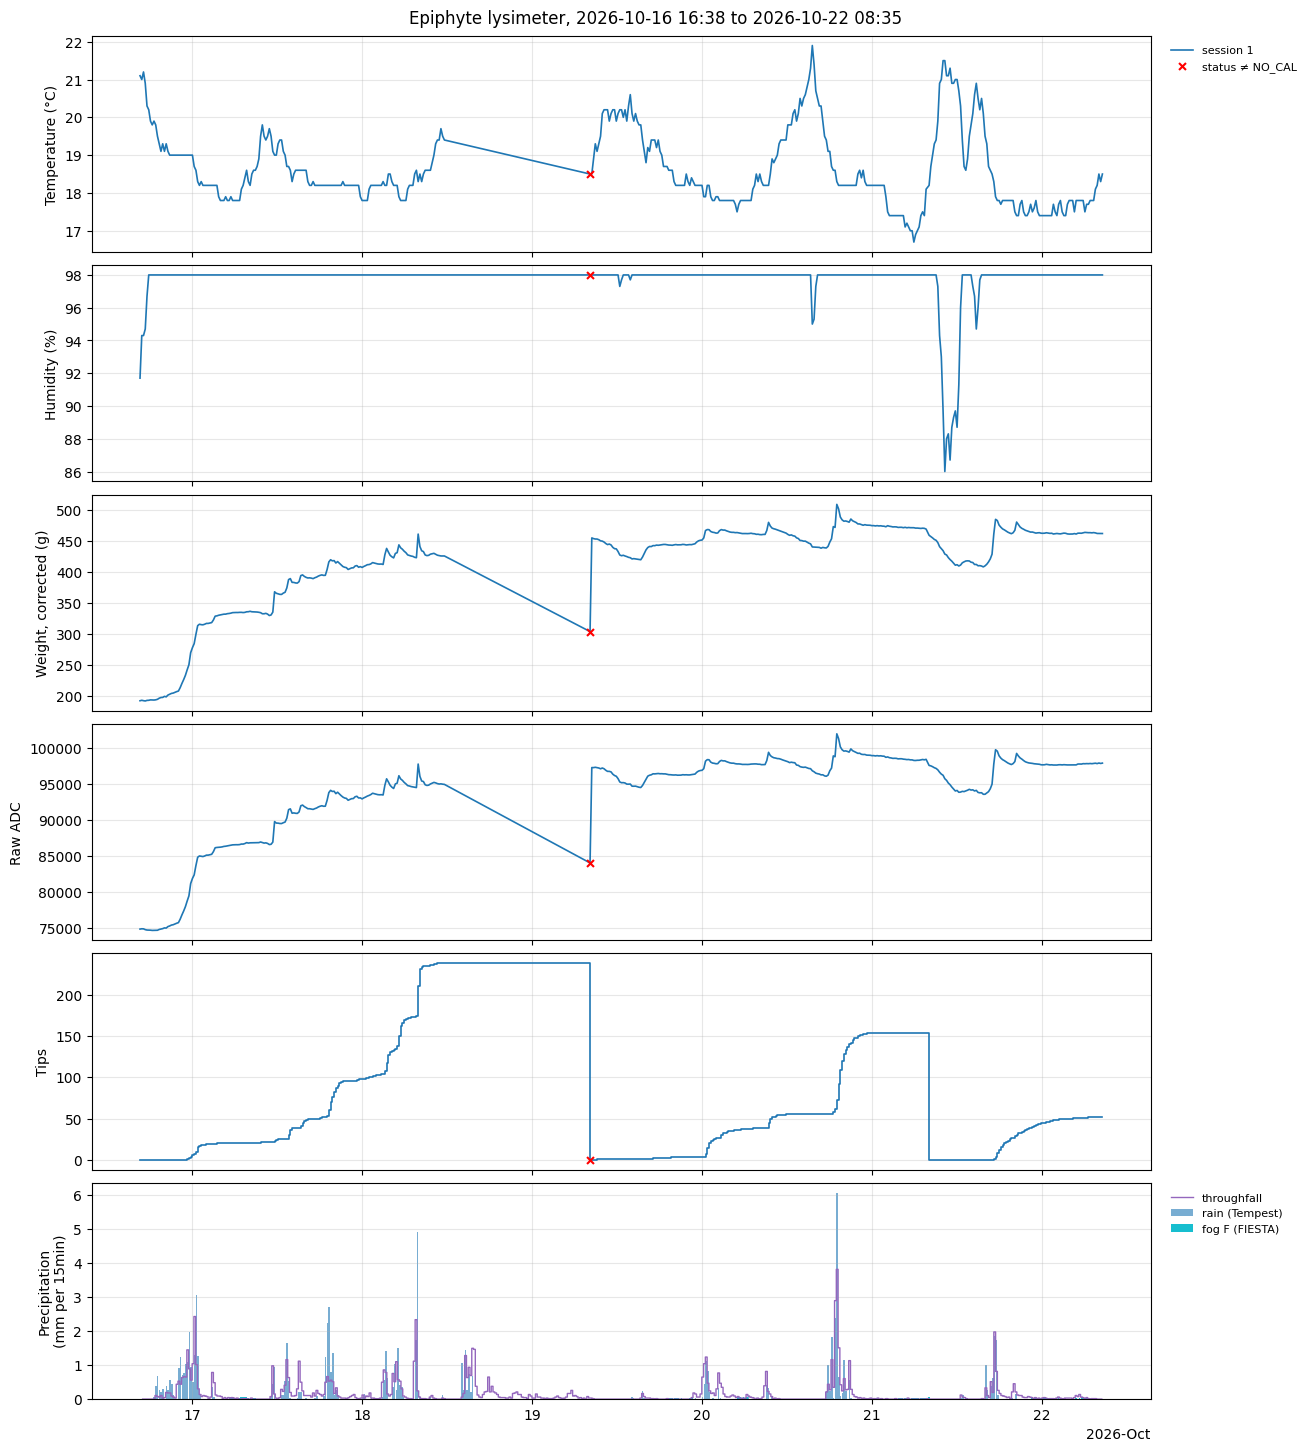

In [6]:
PANELS = [("avg_temperature_C", "Temperature (°C)", "line"),
          ("avg_humidity_pct", "Humidity (%)", "line"),
          ("weight_g", "Weight, corrected (g)", "line"),
          ("avg_raw_adc", "Raw ADC", "line"),
          ("total_tips", "Tips", "step")]
panels = [p for p in PANELS if dw[p[0]].notna().sum() >= MIN_POINTS]
if HAS_RAIN or np.nansum(wb["TF_mm"]) > 0:
    panels.append(("__precip__", f"Precipitation\n(mm per {DT})", "precip"))

if enough(len(dw), "overview") and panels:
    normal = dw["status"].mode().iloc[0]
    flagged = dw[dw["status"] != normal]
    fig, axes = plt.subplots(len(panels), 1, figsize=(13, 2.4 * len(panels)), sharex=True,
                             constrained_layout=True, squeeze=False)
    for ax, (col, label, kind) in zip(axes[:, 0], panels):
        if kind == "precip":
            bw = STEP / pd.Timedelta(days=1)
            if HAS_RAIN:
                ax.bar(wb["start"], wb["rain_mm"], width=bw * 0.9, align="edge", color="tab:blue", alpha=0.6, label=RAIN_NAME)
            ax.step(wb["end"], wb["TF_mm"], where="pre", color="tab:purple", lw=1, label="throughfall")
            ax.bar(wb["start"], wb["F_mm"], width=bw * 0.9, align="edge", color="tab:cyan", label="fog F (FIESTA)")
            ax.set_ylabel(label)
            ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
            continue
        for i, (s, d) in enumerate(dw.groupby("boot_session", sort=False)):
            c = plt.get_cmap("tab10")(i % 10)
            (ax.step(d["timestamp"], d[col], where="post", color=c, lw=1.2, label=f"session {s}")
             if kind == "step" else ax.plot(d["timestamp"], d[col], color=c, lw=1.2, label=f"session {s}"))
        if not flagged.empty:
            ax.scatter(flagged["timestamp"], flagged[col], marker="x", color="red", s=25, zorder=5,
                       label=f"status ≠ {normal}")
        ax.set_ylabel(label)
    axes[0, 0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
    time_axis(axes[-1, 0])
    fig.suptitle(f"Epiphyte lysimeter, {t0:%Y-%m-%d %H:%M} to {t1:%Y-%m-%d %H:%M}")
    finish(fig, "overview")

## 2. Weight: raw vs temperature-corrected

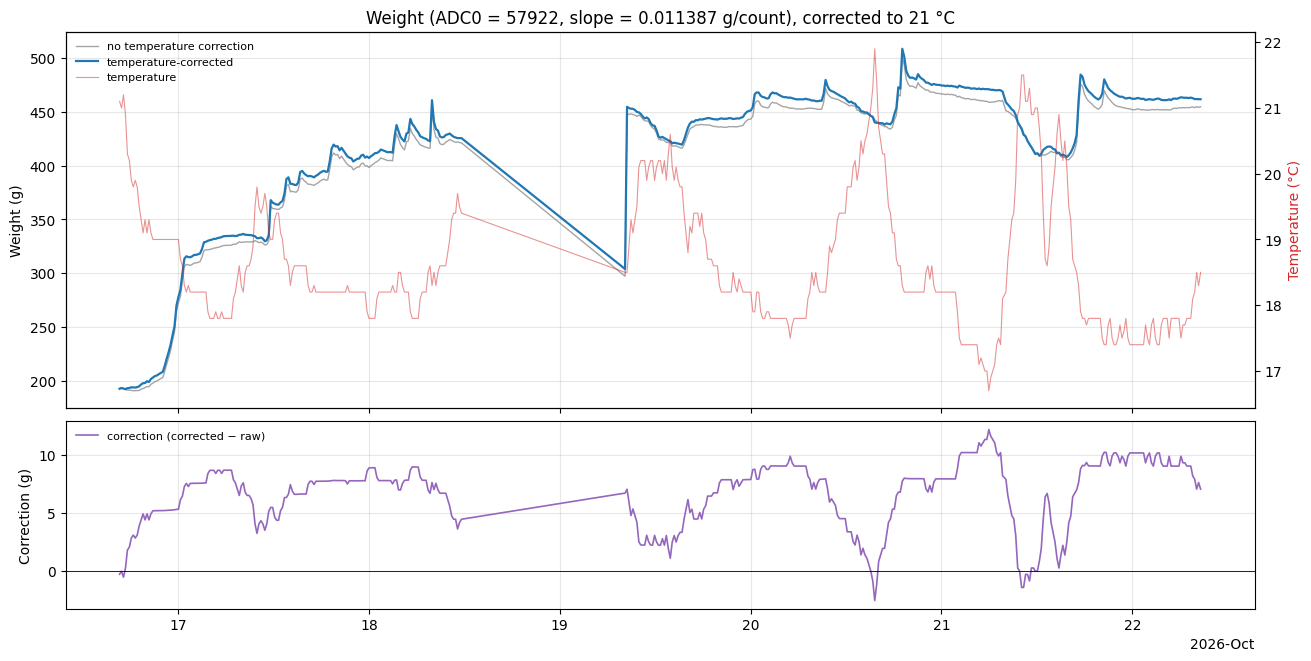

In [7]:
if enough(dw["weight_g"].notna().sum(), "weight with temperature correction"):
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, constrained_layout=True,
                                  gridspec_kw={"height_ratios": [2, 1]})
    for i, (s, g) in enumerate(dw.groupby("boot_session", sort=False)):
        ax.plot(g["timestamp"], g["weight_raw_g"], color="tab:grey", lw=1, alpha=0.7,
                label="no temperature correction" if i == 0 else None)
        ax.plot(g["timestamp"], g["weight_g"], color="tab:blue", lw=1.6,
                label="temperature-corrected" if i == 0 else None)
        ax2.plot(g["timestamp"], g["weight_g"] - g["weight_raw_g"], color="tab:purple", lw=1.2,
                 label="correction (corrected − raw)" if i == 0 else None)
    ax.set_ylabel("Weight (g)")
    tw = add_temperature(ax, dw)
    legend_all(ax, [ax, tw], loc="upper left")
    ax.set_title(f"Weight (ADC0 = {ADC0}, slope = {SLOPE} g/count), corrected to {T_REF} °C")
    ax2.axhline(0, color="k", lw=0.6)
    ax2.set_ylabel("Correction (g)")
    ax2.legend(loc="upper left", fontsize=8, frameon=False)
    time_axis(ax2)
    finish(fig, "weight_temperature")

## 3. Weight with fog periods (fog flag)

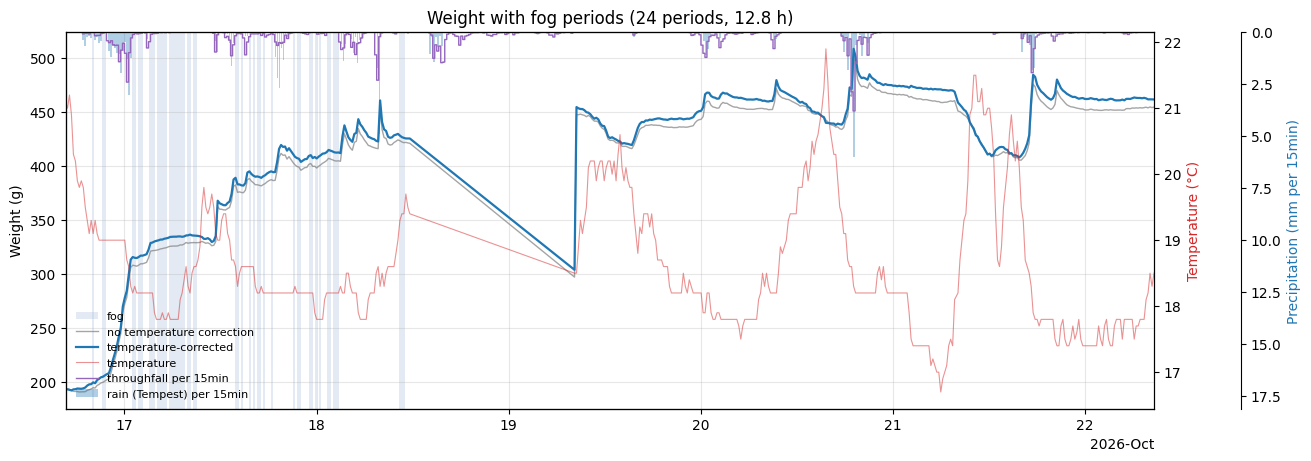

In [8]:
if not fog_periods:
    print("⏭ Skipped 'weight with fog flag': no fog periods in the window")
elif enough(dw["weight_g"].notna().sum(), "weight with fog flag"):
    fig, ax = plt.subplots(figsize=(13, 4.5), constrained_layout=True)
    shade(ax, fog_periods)
    ax.plot(dw["timestamp"], dw["weight_raw_g"], color="tab:grey", lw=1, alpha=0.7, label="no temperature correction")
    ax.plot(dw["timestamp"], dw["weight_g"], color="tab:blue", lw=1.6, label="temperature-corrected")
    ax.set_ylabel("Weight (g)")
    ax.set_xlim(t0, t1)
    tw = add_temperature(ax, dw)
    ar = add_rain(ax)
    legend_all(ax, [a_ for a_ in (ax, tw, ar) if a_ is not None], loc="lower left")
    ax.set_title(f"Weight with fog periods ({len(fog_periods)} periods, {fog_hours:.1f} h)")
    time_axis(ax)
    finish(fig, "weight_fog_flag")

## 4. Weight with FIESTA fog interception and throughfall
FIESTA fog on the plant per record = FIESTA (mm) × `FOG_AREA_CM2` × 0.1 × `EFFICIENCY` (g); as water depth over the
projected area this is × `FOG_AREA_CM2` / `AREA_CM2`. The table balances every fog period:
inputs (TF + F) vs measured mass gain + drainage; the difference is the ET in that period.

FIESTA fog in window: 7.595 mm → expected on plant 77.9 g = 2.86 mm over the projected area | throughfall 83.38 mm


,start,end,hours,F_mm,TF_mm,gain_mm (ΔS),D_mm,ΔS + D (measured),ET_mm,ET ±,ET_mmh
0,2026-10-16 20:00:00,2026-10-16 20:15:00,0.25,0.00,0.05,0.00,-0.01,-0.00,0.05,0.12,0.20
1,2026-10-16 21:15:00,2026-10-16 21:45:00,0.50,0.00,0.09,0.08,-0.01,0.07,0.02,0.12,0.04
2,2026-10-17 01:00:00,2026-10-17 01:30:00,0.50,0.00,0.21,-0.02,0.66,0.64,-0.43,0.12,-0.85
3,2026-10-17 01:45:00,2026-10-17 02:15:00,0.50,0.00,0.17,0.05,0.21,0.26,-0.09,0.12,-0.18
4,2026-10-17 03:00:00,2026-10-17 03:45:00,0.75,0.00,0.69,0.28,0.12,0.41,0.29,0.14,0.38
5,2026-10-17 04:00:00,2026-10-17 05:15:00,1.25,0.00,0.20,0.09,-0.03,0.06,0.14,0.12,0.11
6,2026-10-17 05:30:00,2026-10-17 07:30:00,2.00,0.34,0.15,0.05,-0.02,0.03,0.46,0.21,0.23
7,2026-10-17 07:45:00,2026-10-17 08:15:00,0.50,0.04,0.00,0.02,0.00,0.02,0.01,0.12,0.03
8,2026-10-17 08:30:00,2026-10-17 09:00:00,0.50,0.06,0.00,-0.01,0.00,-0.01,0.07,0.12,0.14
9,2026-10-17 13:45:00,2026-10-17 14:15:00,0.50,0.00,0.29,-0.20,1.81,1.61,-1.32,0.13,-2.65


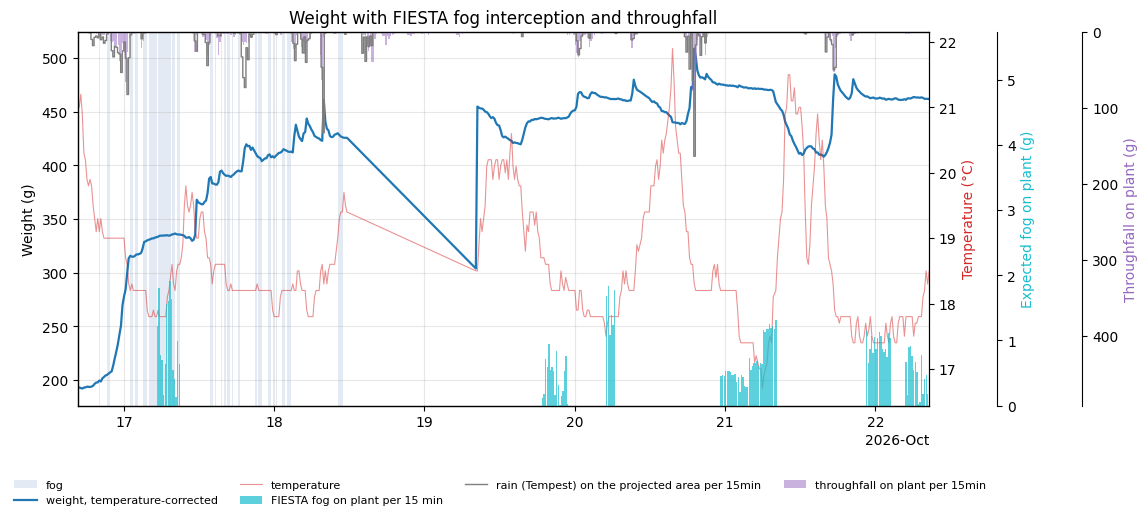

In [9]:
if mw is None or FIESTA_COL not in mw.columns:
    print("⏭ Skipped 'FIESTA fog interception': no weather-station file or FIESTA column")
elif enough(len(mw), "FIESTA fog interception") and enough(dw["weight_g"].notna().sum(), "FIESTA fog interception"):
    G_PER_MM = FOG_AREA_CM2 * 0.1 * EFFICIENCY
    mw["fog_expected_g"] = mw[FIESTA_COL] * G_PER_MM
    print(f"FIESTA fog in window: {mw[FIESTA_COL].sum():.3f} mm → expected on plant {mw['fog_expected_g'].sum():.1f} g "
          f"= {wb['F_mm'].sum():.2f} mm over the projected area | throughfall {np.nansum(wb['TF_mm']):.2f} mm")

    rows = []
    for p, q in fog_periods:
        w = wb[(wb["mid"] >= p) & (wb["mid"] < q)]
        et, sd, h = period_total(w)
        rows.append({"start": p, "end": q, "hours": (q - p).total_seconds() / 3600,
                     "F_mm": w["F_mm"].sum(), "TF_mm": w["TF_mm"].sum(),
                     "gain_mm (ΔS)": w["dS_mm"].sum(), "D_mm": w["D_mm"].sum(),
                     "ΔS + D (measured)": w["dS_mm"].sum() + w["D_mm"].sum(),
                     "ET_mm": et, "ET ±": sd, "ET_mmh": et / h if h else np.nan})
    fog_table = pd.DataFrame(rows)
    if len(fog_table):
        display(fog_table.round({k: 2 for k in fog_table.select_dtypes("number")}))

    fig, ax = plt.subplots(figsize=(13, 5.5))
    shade(ax, fog_periods)
    ax.plot(dw["timestamp"], dw["weight_g"], color="tab:blue", lw=1.6, label="weight, temperature-corrected")
    ax.set_ylabel("Weight (g)")
    ax.set_xlim(t0, t1)
    ax.set_zorder(3); ax.patch.set_visible(False)
    tw = add_temperature(ax, dw)

    off = met_step if MET_LABEL == "end" else pd.Timedelta(0)
    bar_w = met_step / pd.Timedelta(days=1) * 0.9
    ax3 = ax.twinx(); ax3.grid(False)
    ax3.spines["right"].set_position(("axes", 1.08))
    ax3.bar(mw["Timestamp"] - off, mw["fog_expected_g"], width=bar_w, align="edge", color="tab:cyan", alpha=0.7,
            label=f"FIESTA fog on plant per {int(met_step.total_seconds() // 60)} min")
    ax3.set_ylim(0, max(1e-3, mw["fog_expected_g"].max()) * 3)
    ax3.set_ylabel("Expected fog on plant (g)", color="tab:cyan")
    axes_ = [ax, tw, ax3]
    if np.nansum(wb["TF_mm"]) > 0:
        ax4 = ax.twinx(); ax4.grid(False)
        ax4.spines["right"].set_position(("axes", 1.18))
        ax4.bar(wb["start"], wb["TF_mm"] / G2MM, width=STEP / pd.Timedelta(days=1) * 0.9, align="edge",
                color="tab:purple", alpha=0.5, label=f"throughfall on plant per {DT}")
        if HAS_RAIN:
            ax4.step(wb["end"], wb["rain_mm"] / G2MM, where="pre", color="tab:grey", lw=1,
                     label=f"{RAIN_NAME} on the projected area per {DT}")
        ax4.set_ylim(max(1.0, np.nanmax(wb["TF_mm"] / G2MM), np.nanmax(wb["rain_mm"] / G2MM) if HAS_RAIN else 0) * 3, 0)
        ax4.set_ylabel("Throughfall on plant (g)", color="tab:purple")
        axes_.append(ax4)
    legend_all(fig, axes_, loc="lower center", ncol=4, bbox_to_anchor=(0.45, 0.0))
    ax.set_title("Weight with FIESTA fog interception and throughfall")
    time_axis(ax)
    fig.subplots_adjust(right=0.78 if len(axes_) > 3 else 0.85, bottom=0.2)
    finish(fig, "weight_fiesta")

## 5. Throughfall and drainage
How much of the throughfall that reached the epiphyte drained through it, and (if the weather station logs rain)
how throughfall compares with open-field rain. The drainage bucket's funnel is larger than the epiphyte, so the bucket
total = epiphyte drainage + throughfall falling straight into the open part of the funnel (`DIRECT_CM2`).
The cumulative panel and the table show the bucket in its own units (mm over the funnel, as logged, and ml).
Only the epiphyte part is converted to mm over the epiphyte's projected area (`D`), because that is the depth the
balance compares with TF and ΔS; the bucket total itself is never spread over the epiphyte area.

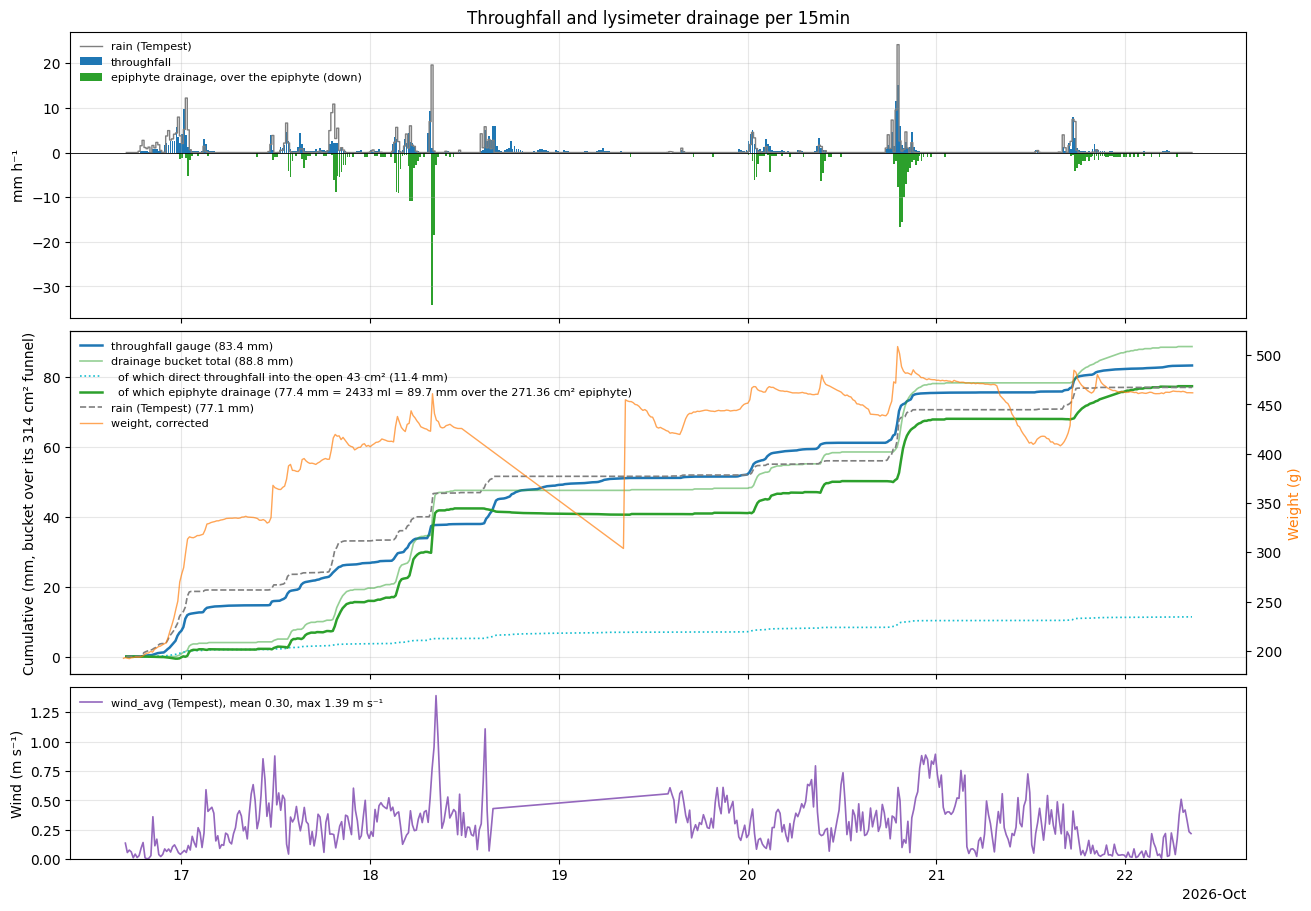

,value
throughfall gauge (mm),83.379
"drainage bucket total (mm over its funnel, as logged)",88.800
direct throughfall into the open funnel (mm over funnel),11.359
epiphyte drainage (mm over funnel),77.441
drainage bucket total (ml),2789.741
direct throughfall into the open funnel (ml),356.863
epiphyte drainage (ml),2432.878
"epiphyte drainage D (mm over the epiphyte, used in the balance)",89.655
throughfall on the epiphyte (ml),2262.576
epiphyte drainage / throughfall,1.075


⚠ The epiphyte drained more (2433 ml) than the throughfall gauge says fell on it (2263 ml). The bucket caught 88.8 mm over its funnel vs 83.4 mm in the throughfall gauge: the lysimeter spot received more water than the gauge (drip point, fog), or the open funnel area (DIRECT_CM2) / DIRECT_SOURCE is off.


In [10]:

EPI2FUN = AREA_CM2 / DRAIN_FUNNEL_CM2                       # mm over the epiphyte -> mm over the drainage funnel (rain-gauge mm)
MM2ML = AREA_CM2 / 10.0                                     # mm over the epiphyte -> ml

if np.nansum(wb["TF_mm"]) <= 0:
    print("⏭ Skipped 'throughfall and drainage': no throughfall in the window")
elif enough(wb["TF_mm"].notna().sum(), "throughfall and drainage"):
    # Wind speed (wind_avg): Tempest file first, else the weather-station file
    wind = None
    for src_df, label, shift_h, name in [(globals().get("td") if tem is not None else None, TEMPEST_LABEL, TEMPEST_SHIFT_H, "Tempest"),
                                         (met, MET_LABEL, 0, "weather station")]:
        if src_df is not None and "wind_avg" in src_df.columns:
            ts = met["Timestamp"] if src_df is met else to_local_naive(src_df[time_col(src_df)]) + pd.Timedelta(hours=shift_h)
            wind = pd.DataFrame({"t": pd.to_datetime(ts).values,
                                 "v": pd.to_numeric(src_df["wind_avg"], errors="coerce").values}).dropna().sort_values("t")
            rec = wind["t"].diff().median()
            if label == "start" and pd.notna(rec):
                wind["t"] += rec / 2                                   # plot each record at its midpoint
            elif pd.notna(rec):
                wind["t"] -= rec / 2
            wind = wind[(wind["t"] >= t0) & (wind["t"] <= t1)]
            WIND_NAME = name
            break
    if wind is None or wind.empty:
        print("⏭ No wind_avg in the Tempest or weather-station file (or none in the window): wind panel skipped")
        fig, (ax, axc) = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True,
                                      gridspec_kw={"height_ratios": [1, 1.2]})
        axw = None
    else:
        fig, (ax, axc, axw) = plt.subplots(3, 1, figsize=(13, 9), sharex=True, constrained_layout=True,
                                           gridspec_kw={"height_ratios": [1, 1.2, 0.6]})
    bw = STEP / pd.Timedelta(days=1) * 0.9
    ax.bar(wb["start"], wb["TF_mmh"], width=bw, align="edge", color="tab:blue", label="throughfall")
    if HAS_RAIN:
        ax.step(wb["end"], wb["rain_mmh"], where="pre", color="tab:grey", lw=1, label=RAIN_NAME)
    ax.bar(wb["start"], -wb["D_mmh"].clip(lower=0), width=bw, align="edge", color="tab:green",
           label="epiphyte drainage, over the epiphyte (down)")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel("mm h⁻¹")
    ax.legend(loc="upper left", fontsize=8, frameon=False)
    ax.set_title(f"Throughfall and lysimeter drainage per {DT}")

    # Cumulative panel in rain-gauge mm over the drainage funnel, so the bucket reads as it was logged (0.2 mm/tip)
    # and bucket total = direct throughfall into the open part + epiphyte drainage
    c_tf, c_d = wb["TF_mm"].fillna(0).cumsum(), wb["D_mm"].fillna(0).cumsum()
    c_b, c_x = wb["Dbucket_mm"].fillna(0).cumsum(), wb["Ddirect_mm"].fillna(0).cumsum()
    g_b, g_x, g_d = c_b * EPI2FUN, c_x * EPI2FUN, c_d * EPI2FUN
    axc.plot(wb["end"], c_tf, color="tab:blue", lw=1.8, label=f"throughfall gauge ({c_tf.iloc[-1]:.1f} mm)")
    axc.plot(wb["end"], g_b, color="tab:green", lw=1.2, alpha=0.5,
             label=f"drainage bucket total ({g_b.iloc[-1]:.1f} mm)")
    axc.plot(wb["end"], g_x, color="tab:cyan", lw=1.2, ls=":",
             label=f"  of which direct throughfall into the open {DIRECT_AREA:.0f} cm² ({g_x.iloc[-1]:.1f} mm)")
    axc.plot(wb["end"], g_d, color="tab:green", lw=1.8,
             label=f"  of which epiphyte drainage ({g_d.iloc[-1]:.1f} mm = {c_d.iloc[-1] * MM2ML:.0f} ml "
                   f"= {c_d.iloc[-1]:.1f} mm over the {AREA_CM2} cm² epiphyte)")
    if wb["rain_mm"].notna().any():
        c_r = wb["rain_mm"].fillna(0).cumsum()
        axc.plot(wb["end"], c_r, color="tab:grey", lw=1.2, ls="--", label=f"{RAIN_NAME} ({c_r.iloc[-1]:.1f} mm)")
    axc.set_ylabel(f"Cumulative (mm, bucket over its {DRAIN_FUNNEL_CM2:.0f} cm² funnel)")
    tw = axc.twinx(); tw.grid(False)
    tw.plot(dw["timestamp"], dw["weight_g"], color="tab:orange", lw=1, alpha=0.7, label="weight, corrected")
    tw.set_ylabel("Weight (g)", color="tab:orange")
    legend_all(axc, [axc, tw], loc="upper left")
    if axw is not None:
        axw.plot(wind["t"], wind["v"], color="tab:purple", lw=1.2,
                 label=f"wind_avg ({WIND_NAME}), mean {wind['v'].mean():.2f}, max {wind['v'].max():.2f} m s⁻¹")
        axw.set_ylabel("Wind (m s⁻¹)")
        axw.set_ylim(bottom=0)
        axw.legend(loc="upper left", fontsize=8, frameon=False)
        time_axis(axw)
    else:
        time_axis(axc)
    finish(fig, "throughfall_drainage")

    stats = {"throughfall gauge (mm)": c_tf.iloc[-1],
             "drainage bucket total (mm over its funnel, as logged)": g_b.iloc[-1],
             "  direct throughfall into the open funnel (mm over funnel)": g_x.iloc[-1],
             "  epiphyte drainage (mm over funnel)": g_d.iloc[-1],
             "drainage bucket total (ml)": c_b.iloc[-1] * MM2ML,
             "  direct throughfall into the open funnel (ml)": c_x.iloc[-1] * MM2ML,
             "  epiphyte drainage (ml)": c_d.iloc[-1] * MM2ML,
             "epiphyte drainage D (mm over the epiphyte, used in the balance)": c_d.iloc[-1],
             "throughfall on the epiphyte (ml)": c_tf.iloc[-1] * MM2ML,
             "epiphyte drainage / throughfall": c_d.iloc[-1] / c_tf.iloc[-1] if c_tf.iloc[-1] else np.nan}
    if wb["rain_mm"].notna().any() and wb["rain_mm"].sum() > 0:
        stats[f"{RAIN_NAME} (mm)"] = wb["rain_mm"].sum()
        stats["throughfall / rain"] = c_tf.iloc[-1] / wb["rain_mm"].sum()
    display(pd.Series(stats).round(3).to_frame("value"))
    if c_tf.iloc[-1] and c_d.iloc[-1] > c_tf.iloc[-1]:
        print(f"⚠ The epiphyte drained more ({c_d.iloc[-1] * MM2ML:.0f} ml) than the throughfall gauge says fell on it "
              f"({c_tf.iloc[-1] * MM2ML:.0f} ml). The bucket caught {g_b.iloc[-1]:.1f} mm over its funnel vs "
              f"{c_tf.iloc[-1]:.1f} mm in the throughfall gauge: the lysimeter spot received more water than the gauge "
              f"(drip point, fog), or the open funnel area (DIRECT_CM2) / DIRECT_SOURCE is off.")

## 6. Water balance closure: TF + F = ΔS + D
Every millimetre that reaches the epiphyte, $P = TF + F$, either stays on it (weight gain $\Delta S$), drains through it
($D$), or evaporates ($ET$). Over a period:

$$\underbrace{TF + F}_{\text{input}} \;=\; \underbrace{\Delta S + D}_{\text{measured by the lysimeter}} \;+\; ET
\qquad \text{closure} = \frac{\Delta S + D}{TF + F}$$

Closure is evaluated for the **whole window**, **per day** and **per wet event**. An event is a run of wet intervals (throughfall
≥ `EVENT_MIN_MM` per Δt, or FIESTA fog > 0), separated by less than `EVENT_GAP`, plus `EVENT_TAIL` afterwards so late drainage is included.
Closure a little below 1 is expected (some water evaporates). Well above 1: the epiphyte received more than TF + F
(drip points in the canopy, fog under-estimated, direct catch in the funnel different from `DIRECT_CM2`).
Well below 1: the gauges over-estimate what reached the plant.

**Drainage of the epiphyte only.** The drainage funnel (`DRAIN_FUNNEL_CM2`) is larger than the epiphyte, so the bucket
also catches precipitation falling straight into its open part (`DIRECT_CM2`). That direct catch is subtracted:
$D = \text{bucket} - P_{direct} \times A_{open}/A_{epi}$, with $P_{direct}$ the throughfall gauge or open-field rain
(`DIRECT_SOURCE`). Two extra columns compare the lysimeter with the gauges in plain rain-gauge mm (over the funnel area):
`bucket_gauge_mm` = bucket total ÷ funnel area (what the bucket reads as a rain gauge, 0.2 mm/tip), `direct_gauge_mm` = the
part of it that is direct throughfall (so epiphyte drainage = `bucket_gauge_mm` − `direct_gauge_mm` in funnel mm, or `D_ml`), and
`lysimeter_catch_mm` = (ΔS + bucket) ÷ funnel area, i.e. all the water that reached the funnel + plant. If the latter is
well above both `TF_mm` and `rain_mm`, the lysimeter spot simply received more water than the gauges (drip point,
wind-driven rain on the plant), not a counting error.

**Is dripping water counted twice?** No. ΔS is the *net* change in weight between the start and the end of each
interval. Water that arrives and drips off within the interval raises the weight and lowers it again, so it adds nothing
to ΔS and is counted only once, in D. Water that arrives in one interval and drips in a later one appears first as
+ΔS and then as −ΔS together with +D, so over the event the +ΔS and −ΔS cancel and only D remains. This holds as long as
the drainage funnel and tipping bucket are **not on the load cell**. Water that has left the plant but has not yet tipped
the bucket is missing from both terms for a while. The bucket holds less than one tip at any time (0.2 mm over its
funnel = 6.3 ml), a mix of drainage and direct throughfall. Because the direct throughfall is subtracted with the gauge,
not taken from the bucket, that unknown volume lands entirely in D: up to 6.3 ml over the epiphyte's projected area
(the upper bound, reached when all of it is drainage, e.g. after the rain stops). It makes single intervals noisy
(see the quality check) but cancels in daily and event totals.

In [11]:
def wet_events():
    wet_ = (wb["TF_mm"].fillna(0) >= EVENT_MIN_MM) | (wb["F_mm"].fillna(0) > 0)      # rain, or any modelled fog
    idx = np.flatnonzero(wet_.to_numpy())
    if not len(idx):
        return []
    n_gap, n_tail = int(pd.Timedelta(EVENT_GAP) / STEP), int(pd.Timedelta(EVENT_TAIL) / STEP)
    ev, a, b = [], idx[0], idx[0]
    for k in idx[1:]:
        if k - b <= n_gap:
            b = k
        else:
            ev.append([a, b]); a = b = k
    ev.append([a, b])
    merged = []
    for a, b in ev:
        b = min(b + n_tail, len(wb) - 1)
        if merged and a <= merged[-1][1] + 1:
            merged[-1][1] = max(merged[-1][1], b)
        else:
            merged.append([a, b])
    return merged


def balance(w, label):
    """Closure and ET over a set of intervals (only intervals with complete data)."""
    v = w[w["ET_mm"].notna()]
    et, sd, h = period_total(v)
    P, dS, D = v["P_mm"].sum(), v["dS_mm"].sum(), v["D_mm"].sum()
    return {"period": label, "start": w["start"].iloc[0], "end": w["end"].iloc[-1], "hours": h,
            "coverage": h / (len(w) * DT_H) if len(w) else np.nan,
            "TF_mm": v["TF_mm"].sum(), "F_mm": v["F_mm"].sum(), "P_mm": P, "rain_mm": v["rain_mm"].sum(min_count=1),
            "ΔS_mm": dS, "D_mm": D, "D_ml": D * MM2ML, "bucket_ml": v["Dbucket_mm"].sum() * MM2ML,
            "bucket_gauge_mm": v["Dbucket_mm"].sum() * EPI2FUN, "direct_gauge_mm": v["Ddirect_mm"].sum() * EPI2FUN,
            "lysimeter_catch_mm": (dS + v["Dbucket_mm"].sum()) * EPI2FUN, "ΔS + D_mm": dS + D,
            "closure": (dS + D) / P if P > 0 else np.nan, "ET_mm": et, "±_mm": sd,
            "ET_mm_per_day": 24 * et / h if h else np.nan}


events = wet_events()
in_event = np.zeros(len(wb), bool)
for a, b in events:
    in_event[a:b + 1] = True

tot_tab = pd.DataFrame([balance(wb, "whole window"),
                        balance(wb[in_event], "during wet events") if in_event.any() else None,
                        balance(wb[~in_event], "between events") if (~in_event).any() else None]).dropna(how="all")
day_tab = pd.DataFrame([balance(g, str(d)) for d, g in wb.groupby(wb["start"].dt.date)])
ev_tab = pd.DataFrame([balance(wb.iloc[a:b + 1], f"event {i + 1}") for i, (a, b) in enumerate(events)])
if len(ev_tab):
    ev_tab["type"] = ["fog only" if r.TF_mm == 0 else ("throughfall only" if r.F_mm == 0 else "throughfall + fog")
                      for r in ev_tab.itertuples()]
for t_ in (tot_tab, day_tab, ev_tab):
    if len(t_) and not HAS_RAIN:
        t_.drop(columns="rain_mm", inplace=True)

show = lambda t_: display(t_.drop(columns=["start", "end"] if t_ is not ev_tab else []).set_index("period")
                          .round({c: 3 for c in t_.select_dtypes("number")}))
print(f"Closure (ΔS + D) / (TF + F) and ET = (TF + F) − (ΔS + D); intervals with complete data only. "
      f"{len(ev_tab)} wet event(s): TF ≥ {EVENT_MIN_MM} mm per {DT} or fog, gap < {EVENT_GAP}, tail {EVENT_TAIL}.")
print("Total:"); show(tot_tab)
print("Per day (coverage = share of the day with complete data):"); show(day_tab)
if len(ev_tab):
    print("Per wet event:"); show(ev_tab)

Closure (ΔS + D) / (TF + F) and ET = (TF + F) − (ΔS + D); intervals with complete data only. 11 wet event(s): TF ≥ 0.1 mm per 15min or fog, gap < 2h, tail 2h.
Total:


,hours,coverage,TF_mm,F_mm,P_mm,rain_mm,ΔS_mm,D_mm,D_ml,bucket_ml,bucket_gauge_mm,direct_gauge_mm,lysimeter_catch_mm,ΔS + D_mm,closure,ET_mm,±_mm,ET_mm_per_day
period,,,,,,,,,,,,,,,,,,
whole window,114.50,0.843,70.211,2.769,72.980,72.445,13.800,91.732,2489.236,2789.741,88.8,9.565,100.720,105.532,1.446,-32.551,8.806,-6.823
during wet events,94.25,0.849,69.941,2.769,72.710,72.195,11.895,91.311,2477.829,2777.174,88.4,9.528,98.675,103.207,1.419,-30.497,8.778,-7.766
between events,20.25,0.818,0.271,0.000,0.271,0.250,1.904,0.420,11.408,12.566,0.4,0.037,2.045,2.325,8.588,-2.054,0.357,-2.435


Per day (coverage = share of the day with complete data):


,hours,coverage,TF_mm,F_mm,P_mm,rain_mm,ΔS_mm,D_mm,D_ml,bucket_ml,bucket_gauge_mm,direct_gauge_mm,lysimeter_catch_mm,ΔS + D_mm,closure,ET_mm,±_mm,ET_mm_per_day
period,,,,,,,,,,,,,,,,,,
2026-10-16,7.25,1.000,7.387,0.000,7.387,12.378,3.091,-0.239,-6.483,25.133,0.8,1.006,3.470,2.852,0.386,4.535,0.864,15.012
2026-10-17,24.00,1.000,19.438,0.543,19.981,20.752,4.809,18.699,507.426,590.621,18.8,2.648,22.954,23.509,1.177,-3.528,2.362,-3.528
2026-10-18,11.50,0.479,11.126,0.000,11.126,13.837,0.681,30.661,832.030,879.648,28.0,1.516,28.588,31.342,2.817,-20.217,1.618,-42.191
2026-10-19,15.75,0.656,1.113,0.266,1.379,0.404,4.519,0.519,14.086,18.850,0.6,0.152,4.504,5.039,3.654,-3.660,0.221,-5.577
2026-10-20,24.00,1.000,23.324,0.382,23.706,18.685,0.859,31.053,842.654,942.480,30.0,3.178,30.742,31.912,1.346,-8.206,2.903,-8.206
2026-10-21,23.50,0.979,6.801,0.960,7.761,6.388,-0.142,9.347,253.637,282.744,9.0,0.926,8.877,9.205,1.186,-1.444,0.988,-1.475
2026-10-22,8.50,1.000,1.023,0.618,1.641,0.001,-0.017,1.691,45.886,50.266,1.6,0.139,1.585,1.674,1.020,-0.033,0.356,-0.092


Per wet event:


,start,end,hours,coverage,TF_mm,F_mm,P_mm,rain_mm,ΔS_mm,D_mm,...,bucket_ml,bucket_gauge_mm,direct_gauge_mm,lysimeter_catch_mm,ΔS + D_mm,closure,ET_mm,±_mm,ET_mm_per_day,type
period,,,,,,,,,,,,,,,,,,,,,
event 1,2026-10-16 18:45:00,2026-10-17 11:00:00,16.25,1.00,14.686,0.543,15.229,18.990,5.022,2.546,...,131.947,4.2,2.001,8.537,7.568,0.497,7.661,1.732,11.315,throughfall + fog
event 2,2026-10-17 11:15:00,2026-10-18 12:00:00,24.25,0.98,23.190,0.000,23.190,27.851,3.432,46.588,...,1363.454,43.4,3.159,46.365,50.020,2.157,-26.830,3.081,-26.554,throughfall only
event 3,2026-10-18 14:15:00,2026-10-19 02:45:00,0.00,0.00,0.000,0.000,0.000,NaN,0.000,0.000,...,0.000,0.0,0.000,0.000,0.000,NaN,NaN,NaN,NaN,fog only
event 4,2026-10-19 05:00:00,2026-10-19 08:15:00,0.00,0.00,0.000,0.000,0.000,NaN,0.000,0.000,...,0.000,0.0,0.000,0.000,0.000,NaN,NaN,NaN,NaN,fog only
event 5,2026-10-19 15:30:00,2026-10-19 17:45:00,2.25,1.00,0.376,0.000,0.376,0.272,0.782,0.172,...,6.283,0.2,0.051,0.875,0.954,2.537,-0.578,0.126,-6.165,throughfall only
event 6,2026-10-19 18:45:00,2026-10-20 08:30:00,13.75,1.00,7.900,0.597,8.497,3.223,0.583,7.090,...,226.195,7.2,1.076,7.704,7.673,0.903,0.824,1.001,1.439,throughfall + fog
event 7,2026-10-20 08:45:00,2026-10-20 11:45:00,3.00,1.00,1.715,0.000,1.715,0.858,0.100,3.434,...,100.531,3.2,0.234,3.286,3.534,2.060,-1.819,0.257,-14.550,throughfall only
event 8,2026-10-20 17:30:00,2026-10-21 10:15:00,16.25,0.97,14.431,0.805,15.235,14.641,0.008,20.647,...,622.037,19.8,1.966,19.807,20.655,1.356,-5.419,1.858,-8.004,throughfall + fog
event 9,2026-10-21 12:30:00,2026-10-21 14:45:00,2.25,1.00,0.241,0.000,0.241,0.160,0.048,-0.038,...,0.000,0.0,0.033,0.042,0.010,0.043,0.230,0.122,2.456,throughfall only


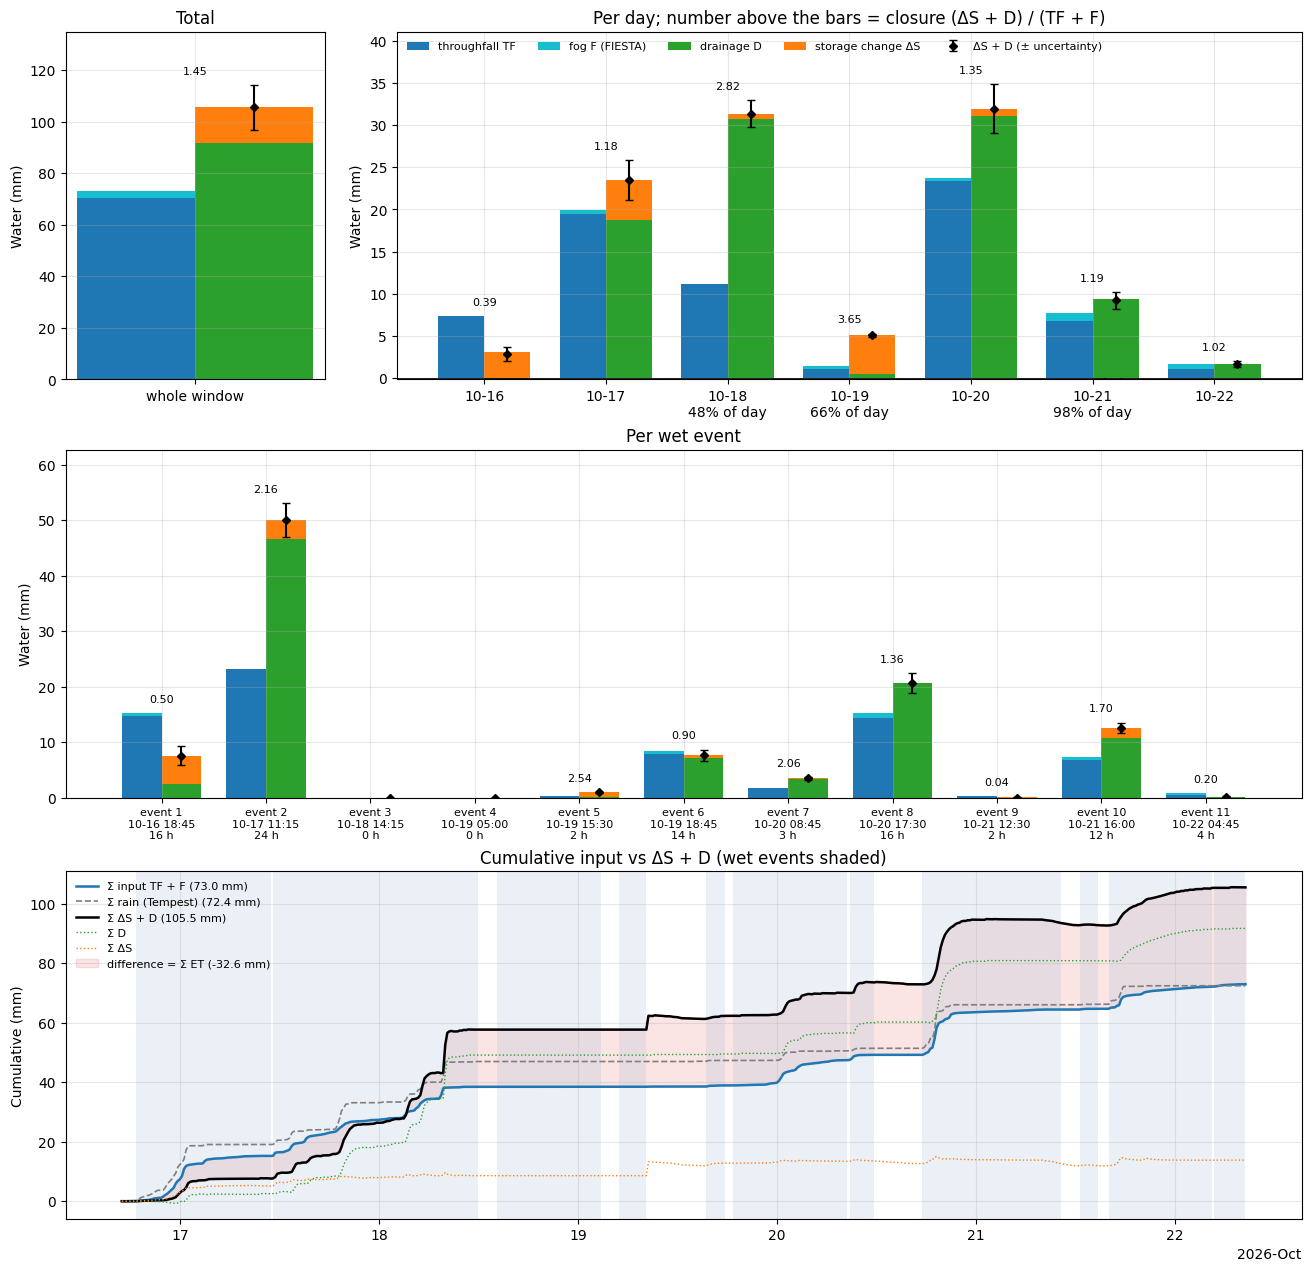

In [12]:
# ---- Figures: closure total / per day / per event, and cumulative ----
def io_bars(ax, x, t_, width=0.38):
    """Input (TF + F) vs measured (D + ΔS) side by side; ◆ = ΔS + D with ±, number = closure."""
    x = np.asarray(x, float)
    ax.bar(x - width / 2, t_["TF_mm"], width, color="tab:blue", label="throughfall TF")
    ax.bar(x - width / 2, t_["F_mm"], width, bottom=t_["TF_mm"], color="tab:cyan", label="fog F (FIESTA)")
    ax.bar(x + width / 2, t_["D_mm"], width, color="tab:green", label="drainage D")
    pos = t_["ΔS_mm"].clip(lower=0)
    ax.bar(x + width / 2, pos, width, bottom=t_["D_mm"].clip(lower=0), color="tab:orange", label="storage change ΔS")
    ax.bar(x + width / 2, t_["ΔS_mm"].clip(upper=0), width, color="tab:orange", alpha=0.5, hatch="//")
    ax.errorbar(x + width / 2, t_["ΔS + D_mm"], yerr=t_["±_mm"], fmt="D", color="k", ms=4, capsize=3,
                label="ΔS + D (± uncertainty)")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel("Water (mm)")


def label_closure(ax, x, t_):
    top = np.nanmax(np.r_[t_["P_mm"], t_["ΔS + D_mm"] + t_["±_mm"]])
    for xi, (_, r) in zip(x, t_.iterrows()):
        if np.isfinite(r["closure"]):
            ax.text(xi, max(r["P_mm"], r["ΔS + D_mm"] + r["±_mm"]) + 0.03 * top, f"{r['closure']:.2f}",
                    ha="center", va="bottom", fontsize=8)
    ax.set_ylim(min(0, np.nanmin(t_["ΔS_mm"]) * 1.2), top * 1.18)


if valid.sum() >= MIN_POINTS:
    n_row = 3 if len(ev_tab) else 2
    fig = plt.figure(figsize=(13, 4.2 * n_row), constrained_layout=True)
    gs = fig.add_gridspec(n_row, 4)
    axT = fig.add_subplot(gs[0, 0]); axD = fig.add_subplot(gs[0, 1:])
    t_ = tot_tab.iloc[[0]]
    io_bars(axT, [0], t_); label_closure(axT, [0], t_)
    axT.set_xticks([0], ["whole window"]); axT.set_title("Total")
    io_bars(axD, range(len(day_tab)), day_tab); label_closure(axD, range(len(day_tab)), day_tab)
    axD.set_xticks(range(len(day_tab)),
                   [f"{p[5:]}\n{c:.0%} of day" if c < 0.99 else p[5:] for p, c in zip(day_tab["period"], day_tab["coverage"])])
    axD.set_title("Per day; number above the bars = closure (ΔS + D) / (TF + F)")
    h_, l_ = axD.get_legend_handles_labels()
    axD.legend(h_[:5], l_[:5], fontsize=8, frameon=False, ncol=5, loc="upper left")
    if len(ev_tab):
        axE = fig.add_subplot(gs[1, :])
        io_bars(axE, range(len(ev_tab)), ev_tab); label_closure(axE, range(len(ev_tab)), ev_tab)
        axE.set_xticks(range(len(ev_tab)), [f"{r.period}\n{r.start:%m-%d %H:%M}\n{r.hours:.0f} h"
                                              for r in ev_tab.itertuples()], fontsize=8)
        axE.set_title("Per wet event")
    axC = fig.add_subplot(gs[-1, :])
    v = wb["ET_mm"].notna()
    cP = wb["P_mm"].where(v, 0).cumsum()
    cR = (wb["dS_mm"] + wb["D_mm"]).where(v, 0).cumsum()
    axC.plot(wb["end"], cP, color="tab:blue", lw=1.8, label=f"Σ input TF + F ({cP.iloc[-1]:.1f} mm)")
    if HAS_RAIN:
        cRain = wb["rain_mm"].where(v, 0).fillna(0).cumsum()
        axC.plot(wb["end"], cRain, color="tab:grey", lw=1.2, ls="--", label=f"Σ {RAIN_NAME} ({cRain.iloc[-1]:.1f} mm)")
    axC.plot(wb["end"], cR, color="k", lw=1.8, label=f"Σ ΔS + D ({cR.iloc[-1]:.1f} mm)")
    axC.plot(wb["end"], wb["D_mm"].where(v, 0).cumsum(), color="tab:green", lw=1, ls=":", label="Σ D")
    axC.plot(wb["end"], wb["dS_mm"].where(v, 0).cumsum(), color="tab:orange", lw=1, ls=":", label="Σ ΔS")
    axC.fill_between(wb["end"], cR, cP, color="tab:red", alpha=0.12, label=f"difference = Σ ET ({cP.iloc[-1] - cR.iloc[-1]:.1f} mm)")
    for a, b in events:
        axC.axvspan(wb["start"].iloc[a], wb["end"].iloc[b], color="lightsteelblue", alpha=0.25, lw=0)
    axC.set_ylabel("Cumulative (mm)")
    axC.set_title("Cumulative input vs ΔS + D (wet events shaded)")
    axC.legend(fontsize=8, frameon=False, loc="upper left")
    time_axis(axC)
    finish(fig, "closure")

## 7. Evapotranspiration from the 15-min water balance
$ET = (TF + F) - D_{epi} - \Delta S_{epi}/\Delta t$ for every interval, as mean rates in mm h⁻¹.
Totals per day sum the intervals with complete data. Negative ET = more water gained than the measured inputs explain.

,value
TF (mm),70.211
F (FIESTA) (mm),2.769
P = TF + F (mm),72.980
D (drainage) (mm),91.732
ΔS (storage change) (mm),13.800
ET (mm),-32.551
ET ± (mm),8.806
hours with ET,114.500
mean ET rate (mm/h),-0.284
ET per day (mm/d),-6.823


Per date (only intervals with complete data; incomplete days are scaled to 24 h in the last column):


,hours,TF_mm,F_mm,P_mm,D_mm,dS_mm,ET_mm,ET_sd_mm,ET_mm_per_24h
start,,,,,,,,,
2026-10-16,7.25,7.39,0.00,7.39,-0.24,3.09,4.53,0.86,15.01
2026-10-17,24.00,19.44,0.54,19.98,18.70,4.81,-3.53,2.36,-3.53
2026-10-18,11.50,11.13,0.00,11.13,30.66,0.68,-20.22,1.62,-42.19
2026-10-19,15.75,1.11,0.27,1.38,0.52,4.52,-3.66,0.22,-5.58
2026-10-20,24.00,23.32,0.38,23.71,31.05,0.86,-8.21,2.90,-8.21
2026-10-21,23.50,6.80,0.96,7.76,9.35,-0.14,-1.44,0.99,-1.47
2026-10-22,8.50,1.02,0.62,1.64,1.69,-0.02,-0.03,0.36,-0.09


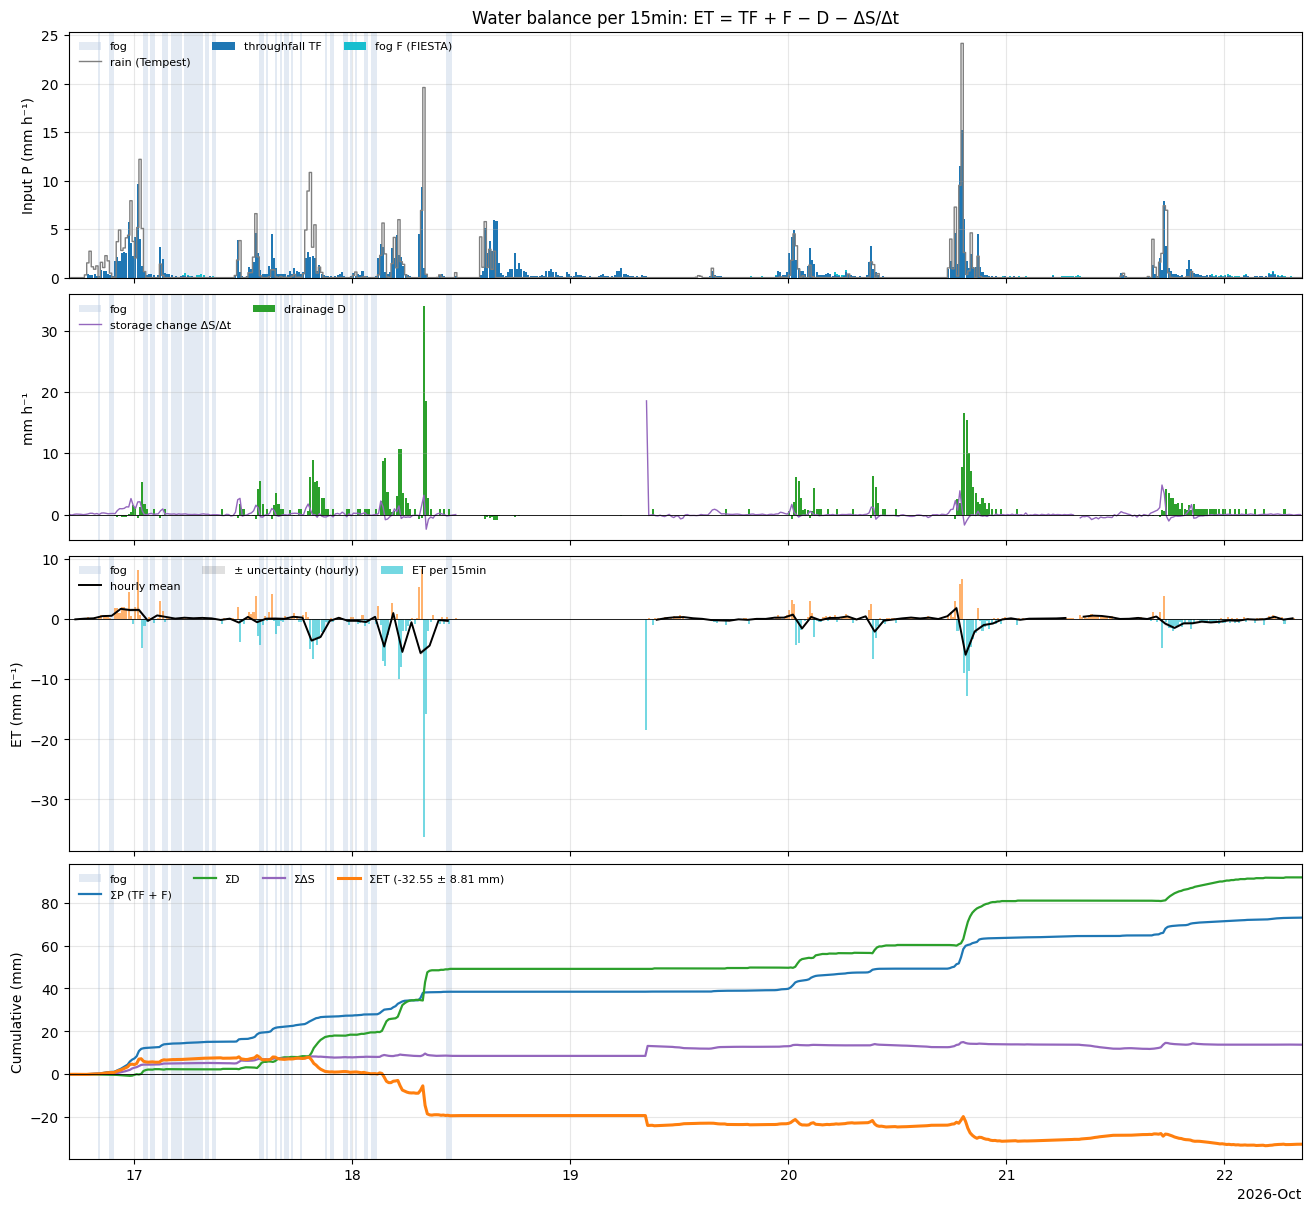

Saved lys2_water_balance_15min.csv


In [13]:
if enough(valid.sum(), "15-min water balance"):
    tot = {}
    for name, col in [("TF", "TF_mm"), ("F (FIESTA)", "F_mm"), ("P = TF + F", "P_mm"), ("D (drainage)", "D_mm"),
                      ("ΔS (storage change)", "dS_mm")]:
        tot[f"{name} (mm)"] = wb.loc[valid, col].sum()
    et, sd, h = period_total(wb)
    tot.update({"ET (mm)": et, "ET ± (mm)": sd, "hours with ET": h,
                "mean ET rate (mm/h)": et / h if h else np.nan,
                "ET per day (mm/d)": 24 * et / h if h else np.nan,
                "ET (g, whole plant)": et / G2MM})
    display(pd.Series(tot).round(3).to_frame("value"))

    daily = wb[valid].groupby(wb.loc[valid, "start"].dt.date).agg(
        hours=("ET_mm", lambda s: len(s) * DT_H), TF_mm=("TF_mm", "sum"), F_mm=("F_mm", "sum"),
        P_mm=("P_mm", "sum"), D_mm=("D_mm", "sum"), dS_mm=("dS_mm", "sum"), ET_mm=("ET_mm", "sum"))
    daily["ET_sd_mm"] = [period_total(wb[valid & (wb["start"].dt.date == d)])[1] for d in daily.index]
    daily["ET_mm_per_24h"] = daily["ET_mm"] * 24 / daily["hours"]
    print("Per date (only intervals with complete data; incomplete days are scaled to 24 h in the last column):")
    display(daily.round(2))

    # ---- Components and ET, per interval ----
    fig, axs = plt.subplots(4, 1, figsize=(13, 12), sharex=True, constrained_layout=True,
                            gridspec_kw={"height_ratios": [1, 1, 1.2, 1.2]})
    for a_ in axs:
        shade(a_, fog_periods)
    bw = STEP / pd.Timedelta(days=1) * 0.9
    axs[0].bar(wb["start"], wb["TF_mmh"], width=bw, align="edge", color="tab:blue", label="throughfall TF")
    axs[0].bar(wb["start"], wb["F_mmh"], width=bw, align="edge", bottom=wb["TF_mmh"].fillna(0),
               color="tab:cyan", label="fog F (FIESTA)")
    if HAS_RAIN:
        axs[0].step(wb["end"], wb["rain_mmh"], where="pre", color="tab:grey", lw=1, label=RAIN_NAME)
    axs[0].set_ylabel("Input P (mm h⁻¹)")
    axs[0].legend(loc="upper left", fontsize=8, frameon=False, ncol=3)
    axs[0].set_title(f"Water balance per {DT}: ET = TF + F − D − ΔS/Δt")

    axs[1].bar(wb["start"], wb["D_mmh"], width=bw, align="edge", color="tab:green", label="drainage D")
    axs[1].plot(wb["mid"], wb["dS_mmh"], color="tab:purple", lw=1, label="storage change ΔS/Δt")
    axs[1].axhline(0, color="k", lw=0.6)
    axs[1].set_ylabel("mm h⁻¹")
    axs[1].legend(loc="upper left", fontsize=8, frameon=False, ncol=2)

    axs[2].bar(wb["start"], wb["ET_mmh"], width=bw, align="edge",
               color=np.where(wb["ET_mmh"] >= 0, "tab:orange", "tab:cyan"), alpha=0.6, label=f"ET per {DT}")
    # complete hours only; gaps stay gaps in the line
    hh = wh.set_index("start")[["ET_mmh", "ET_sd_mmh"]].reindex(
        pd.date_range(wb["start"].min().floor("1h"), wb["end"].max(), freq="1h"))
    xh = hh.index + pd.Timedelta(minutes=30)
    axs[2].plot(xh, hh["ET_mmh"], color="k", lw=1.4, label="hourly mean")
    axs[2].fill_between(xh, hh["ET_mmh"] - hh["ET_sd_mmh"], hh["ET_mmh"] + hh["ET_sd_mmh"],
                        color="k", alpha=0.12, lw=0, label="± uncertainty (hourly)")
    axs[2].axhline(0, color="k", lw=0.6)
    axs[2].set_ylabel("ET (mm h⁻¹)")
    axs[2].legend(loc="upper left", fontsize=8, frameon=False, ncol=3)

    cum = lambda c: wb[c].where(valid, 0).cumsum()
    axs[3].plot(wb["end"], cum("P_mm"), color="tab:blue", lw=1.6, label="ΣP (TF + F)")
    axs[3].plot(wb["end"], cum("D_mm"), color="tab:green", lw=1.6, label="ΣD")
    axs[3].plot(wb["end"], cum("dS_mm"), color="tab:purple", lw=1.6, label="ΣΔS")
    axs[3].plot(wb["end"], cum("ET_mm"), color="tab:orange", lw=2.2, label=f"ΣET ({et:.2f} ± {sd:.2f} mm)")
    axs[3].axhline(0, color="k", lw=0.6)
    axs[3].set_ylabel("Cumulative (mm)")
    axs[3].legend(loc="upper left", fontsize=8, frameon=False, ncol=4)
    axs[0].set_xlim(wb["start"].min(), wb["end"].max())
    time_axis(axs[3])
    finish(fig, "water_balance")

    if SAVE_CSV:
        out = DATA_PATH.with_name(f"{DATA_PATH.stem}_water_balance_{DT}.csv")
        wb.to_csv(out, index=False)
        print(f"Saved {out}")

### ET per day, per wet event and in total
$ET = (TF + F) - \Delta S - D$ summed over each period (same numbers as the closure tables above).
Bars show ET with its uncertainty; partial days are labelled with their data coverage and also given as mm/day.
**Mass loss in dry periods** (at least `DRY_MIN` with no input and no drainage, outside wet events) is the weight loss
alone, so it is an ET estimate that does not depend on the throughfall gauge or FIESTA.

Dry periods ≥ 2h (weight loss = evaporation):


,start,end,hours,part,mass loss (g),ET (mm),ET rate (mm/h),± (mm/h),mean RH (%)
0,2026-10-19 09:15:00,2026-10-19 15:15:00,6.00,day,32.877,1.212,0.202,0.004,97.946
1,2026-10-20 12:00:00,2026-10-20 17:30:00,5.50,day,23.005,0.848,0.154,0.005,97.713
2,2026-10-21 10:15:00,2026-10-21 12:30:00,2.25,day,19.744,0.728,0.323,0.011,88.809


ET in total and by day part:


,hours,P_mm,ΔS_mm,D_mm,ET_mm,±_mm,ET_mm_per_day
period,,,,,,,
total,114.5,72.980,13.800,91.732,-32.551,8.806,-6.823
day (06–18),54.5,20.955,5.999,27.411,-12.455,2.558,-5.485
night (18–06),60.0,52.025,7.801,64.321,-20.096,6.276,-8.039


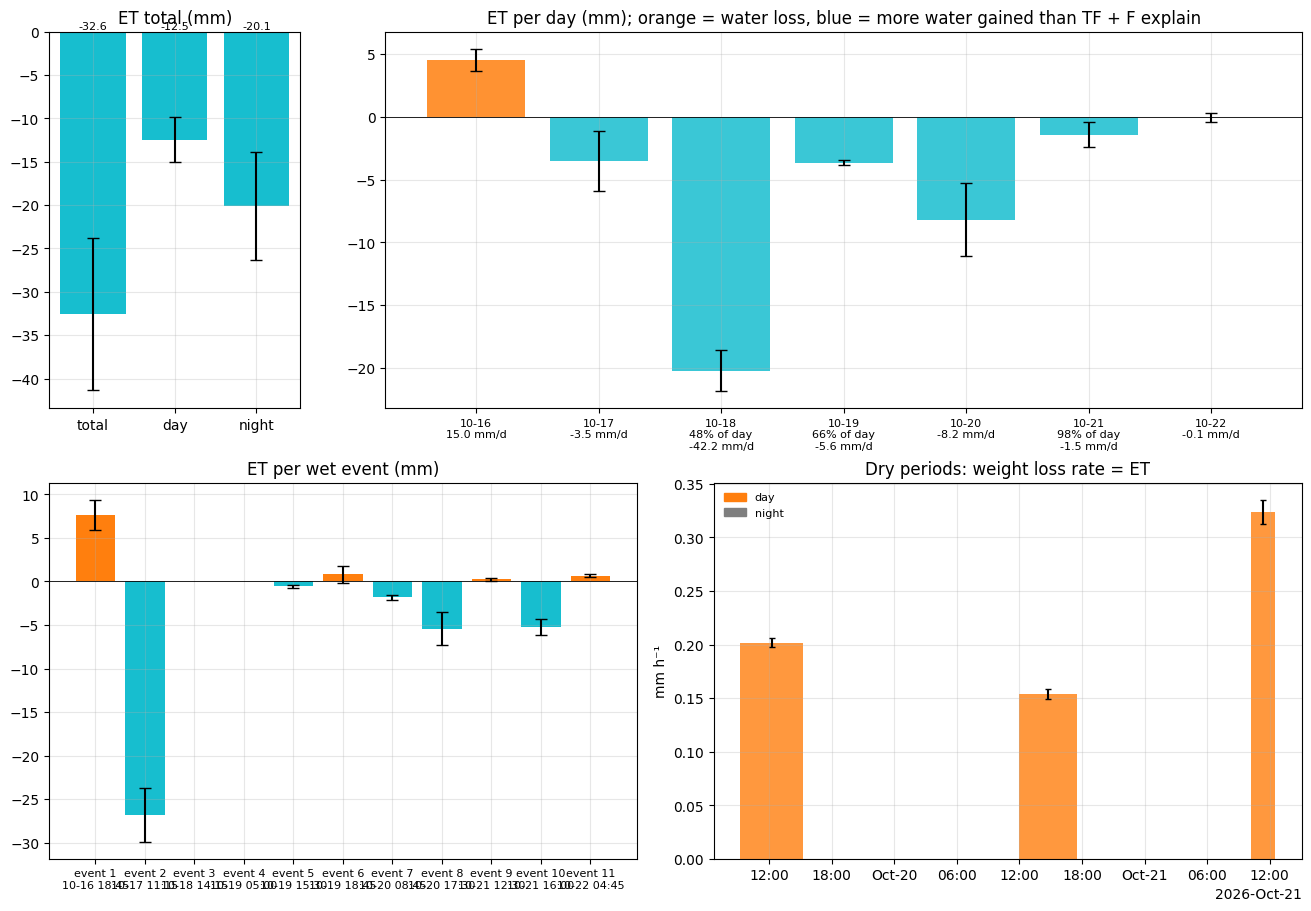

In [14]:
# Dry periods: no input, no drainage, outside wet events, mass available
dry = (~in_event) & (wb["P_mm"].fillna(0) == 0) & (wb["Dbucket_mm"].fillna(0) == 0) & wb["dS_mm"].notna()
run = ((dry != dry.shift()) | (wb["day"] != wb["day"].shift())).cumsum()   # split at day/night boundaries
n_dry = int(pd.Timedelta(DRY_MIN) / STEP)
drows = []
for _, w in wb[dry].groupby(run[dry]):
    if len(w) < n_dry:
        continue
    loss = -w["dS_mm"].sum()
    h = len(w) * DT_H
    drows.append({"start": w["start"].iloc[0], "end": w["end"].iloc[-1], "hours": h,
                  "part": "day" if w["day"].iloc[0] else "night", "mass loss (g)": loss / G2MM,
                  "ET (mm)": loss, "ET rate (mm/h)": loss / h, "± (mm/h)": sig_S / h,
                  "mean RH (%)": np.interp(w["mid"].astype("int64"), dw["timestamp"].astype("int64"),
                                           dw["avg_humidity_pct"]).mean()})
dry_tab = pd.DataFrame(drows)
if len(dry_tab):
    print(f"Dry periods ≥ {DRY_MIN} (weight loss = evaporation):")
    display(dry_tab.round({c: 3 for c in dry_tab.select_dtypes("number")}))
else:
    print(f"No dry periods of at least {DRY_MIN} (no input and no drainage) in the window.")

parts = pd.DataFrame([balance(wb, "total"), balance(wb[wb["day"]], "day (06–18)"),
                      balance(wb[~wb["day"]], "night (18–06)")])
print("ET in total and by day part:")
display(parts.set_index("period")[["hours", "P_mm", "ΔS_mm", "D_mm", "ET_mm", "±_mm", "ET_mm_per_day"]].round(3))

if valid.sum() >= MIN_POINTS:
    n_row = 2
    fig = plt.figure(figsize=(13, 9), constrained_layout=True)
    gs = fig.add_gridspec(n_row, 4)
    axT, axD = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1:])
    col = lambda e: np.where(np.asarray(e) >= 0, "tab:orange", "tab:cyan")
    axT.bar(range(3), parts["ET_mm"], yerr=parts["±_mm"], capsize=4, color=col(parts["ET_mm"]))
    axT.set_xticks(range(3), ["total", "day", "night"])
    for i, r in parts.iterrows():
        axT.text(i, max(r["ET_mm"] + r["±_mm"], 0), f"{r['ET_mm']:.1f}", ha="center", va="bottom", fontsize=8)
    axT.set_title("ET total (mm)")
    axD.bar(range(len(day_tab)), day_tab["ET_mm"], yerr=day_tab["±_mm"], capsize=4, color=col(day_tab["ET_mm"]),
            alpha=0.85)
    axD.set_xticks(range(len(day_tab)),
                   [f"{p[5:]}\n{c:.0%} of day\n{e:.1f} mm/d" if c < 0.99 else f"{p[5:]}\n{e:.1f} mm/d"
                    for p, c, e in zip(day_tab["period"], day_tab["coverage"], day_tab["ET_mm_per_day"])], fontsize=8)
    axD.set_title("ET per day (mm); orange = water loss, blue = more water gained than TF + F explain")
    if len(ev_tab):
        axE = fig.add_subplot(gs[1, :2])
        axE.bar(range(len(ev_tab)), ev_tab["ET_mm"], yerr=ev_tab["±_mm"], capsize=4, color=col(ev_tab["ET_mm"]))
        axE.set_xticks(range(len(ev_tab)), [f"{r.period}\n{r.start:%m-%d %H:%M}" for r in ev_tab.itertuples()], fontsize=8)
        axE.set_title("ET per wet event (mm)")
    else:
        axE = fig.add_subplot(gs[1, :2]); axE.text(0.5, 0.5, "no wet events", ha="center", transform=axE.transAxes)
    axM = fig.add_subplot(gs[1, 2:])
    if len(dry_tab):
        bw = (dry_tab["end"] - dry_tab["start"]) / pd.Timedelta(days=1)
        axM.bar(dry_tab["start"], dry_tab["ET rate (mm/h)"], width=bw, align="edge", yerr=dry_tab["± (mm/h)"], capsize=2,
                color=np.where(dry_tab["part"] == "day", "tab:orange", "tab:grey"), alpha=0.8)
        from matplotlib.patches import Patch
        axM.legend(handles=[Patch(color="tab:orange", label="day"), Patch(color="tab:grey", label="night")],
                   fontsize=8, frameon=False)
        time_axis(axM)
    else:
        axM.text(0.5, 0.5, f"no dry periods ≥ {DRY_MIN}", ha="center", transform=axM.transAxes)
    axM.set_ylabel("mm h⁻¹"); axM.set_title("Dry periods: weight loss rate = ET")
    for a_ in (axT, axD, axE, axM):
        a_.axhline(0, color="k", lw=0.6)
    finish(fig, "et_summary")

## 8. Comparisons
- **Temperature correction**: ET from corrected vs raw mass.
- **Input terms**: full balance (TF + F) vs throughfall only (no fog) vs no inputs (mass loss − drainage, the lab method).
  The gap between them is how much ET the inputs explain.
- **Conditions**: mean ET rate with / without fog (flag and FIESTA), during throughfall vs dry, day vs night.

,ET (mm),± (mm),mm/day
variant,,,
"full balance, corrected mass",-32.551,8.806,-6.823
"full balance, raw mass",-32.307,8.806,-6.772
throughfall only (no fog F),-35.321,8.806,-7.403
no inputs (mass loss − drainage),-105.532,8.806,-22.120


,hours,ET (mm),± (mm),mean ET (mm/h),± (mm/h),share negative
condition,,,,,,
fog flag,12.75,-2.258,0.732,-0.177,0.057,0.412
no fog flag,101.75,-30.293,8.413,-0.298,0.083,0.369
FIESTA fog > 0,25.75,1.836,1.440,0.071,0.056,0.175
FIESTA fog = 0,88.75,-34.387,8.459,-0.387,0.095,0.431
throughfall > 0,73.75,-36.561,8.732,-0.496,0.118,0.464
no throughfall,40.75,4.010,0.914,0.098,0.022,0.209
day,54.50,-12.455,2.558,-0.229,0.047,0.294
night,60.00,-20.096,6.276,-0.335,0.105,0.446
"dry day (no fog, no TF)",25.00,3.568,0.460,0.143,0.018,0.210


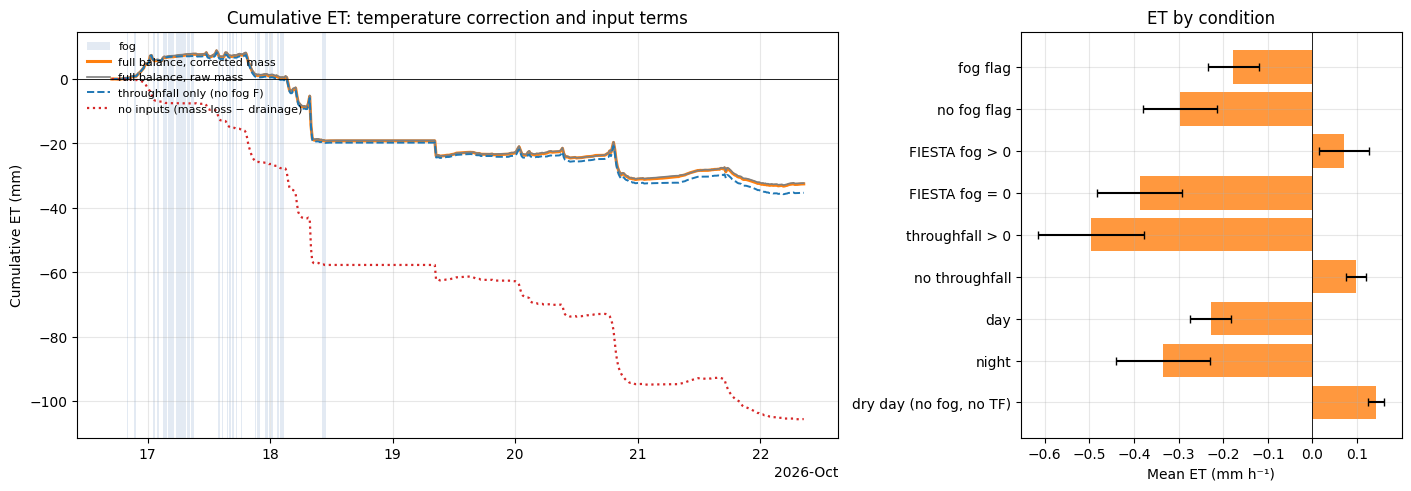

Fog flag on but FIESTA = 0 for 9.8 h; FIESTA > 0 without fog flag for 23.2 h.


In [15]:
if enough(valid.sum(), "comparisons"):
    variants = [("ET_mm", "full balance, corrected mass", "tab:orange", "-", 2.2),
                ("ET_raw_mm", "full balance, raw mass", "tab:grey", "-", 1.2),
                ("ET_TF_mm", "throughfall only (no fog F)", "tab:blue", "--", 1.4),
                ("ET_noP_mm", "no inputs (mass loss − drainage)", "tab:red", ":", 1.6)]
    rows = []
    for col, label, *_ in variants:
        v, sd, h = period_total(wb, col)
        rows.append({"variant": label, "ET (mm)": v, "± (mm)": sd, "mm/day": 24 * v / h if h else np.nan})
    display(pd.DataFrame(rows).set_index("variant").round(3))

    conds = [("fog flag", wb["fog"]), ("no fog flag", ~wb["fog"]),
             ("FIESTA fog > 0", wb["fiesta"]), ("FIESTA fog = 0", ~wb["fiesta"]),
             ("throughfall > 0", wb["wet"]), ("no throughfall", ~wb["wet"]),
             ("day", wb["day"]), ("night", ~wb["day"]),
             ("dry day (no fog, no TF)", wb["day"] & ~wb["fog"] & ~wb["wet"] & ~wb["fiesta"])]
    rows = []
    for name, m in conds:
        w = wb[m & valid]
        v, sd, h = period_total(w)
        rows.append({"condition": name, "hours": h, "ET (mm)": v, "± (mm)": sd,
                     "mean ET (mm/h)": v / h if h else np.nan, "± (mm/h)": sd / h if h else np.nan,
                     "share negative": (w["ET_mm"] < 0).mean() if len(w) else np.nan})
    cond_table = pd.DataFrame(rows).set_index("condition")
    display(cond_table.round(3))

    fig, (axc, axb) = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True,
                                   gridspec_kw={"width_ratios": [2, 1]})
    shade(axc, fog_periods)
    for col, label, color, ls, lw in variants:
        axc.plot(wb["end"], wb[col].where(valid, 0).cumsum(), color=color, ls=ls, lw=lw, label=label)
    axc.axhline(0, color="k", lw=0.6)
    axc.set_ylabel("Cumulative ET (mm)")
    axc.set_title("Cumulative ET: temperature correction and input terms")
    axc.legend(loc="upper left", fontsize=8, frameon=False)
    time_axis(axc)

    ct = cond_table[cond_table["hours"] > 0]
    axb.barh(ct.index[::-1], ct["mean ET (mm/h)"][::-1], xerr=ct["± (mm/h)"][::-1],
             color="tab:orange", alpha=0.8, capsize=3)
    axb.axvline(0, color="k", lw=0.6)
    axb.set_xlabel("Mean ET (mm h⁻¹)")
    axb.set_title("ET by condition")
    finish(fig, "et_comparison")

    if fog_periods and (wb["fog"] & ~wb["fiesta"]).any():
        print(f"Fog flag on but FIESTA = 0 for {(wb['fog'] & ~wb['fiesta']).sum() * DT_H:.1f} h; "
              f"FIESTA > 0 without fog flag for {(~wb['fog'] & wb['fiesta']).sum() * DT_H:.1f} h.")

## 9. Quality check: hours the balance cannot explain
Checked on complete hours (single 15-min intervals are too noisy). Hours where ET is more than `K_SIGMA`·σ below zero
gained more water than TF + F explain (fog under-estimated by FIESTA, throughfall under-catch, dew, a disturbance).
Hours with unusually high ET during inputs can mean the inputs are over-estimated (e.g. throughfall that missed the plant).
Drainage registers slightly after the water reaches the plant (it has to run through the plant and fill the bucket),
so the check uses a lagged balance: drainage counted at time t is attributed to t − lag (`DRAIN_LAG`, by default the lag where input and drainage match best). Without this, the hour
when the delayed drainage tips looks like a gain. Consecutive flagged hours are grouped into episodes.

In [16]:
if enough(len(wh), "quality check (complete hours)"):
    E = wh["ET_lag_mm"].fillna(wh["ET_mm"])          # balance with drainage moved back by DRAIN_LAG
    neg = E < -K_SIGMA * wh["ET_sd_mm"]
    ref = wh.loc[wh["day"] & ~wh["wet"] & ~wh["fog"], "ET_mmh"]
    hi_ref = ref.quantile(0.95) if len(ref) else np.inf
    pos = (wh["P_mm"] > 0) & (E > K_SIGMA * wh["ET_sd_mm"]) & (E / ((wh["end"] - wh["start"]) / pd.Timedelta(hours=1)) > hi_ref)
    n_neg0 = (wh["ET_mm"] < -K_SIGMA * wh["ET_sd_mm"]).sum()
    print(f"Detection limit ≈ {K_SIGMA * wh['ET_sd_mmh'].median():.2f} mm/h per hour. "
          f"{neg.sum()} hour(s) with significant negative ET, {pos.sum()} with unusually high ET during inputs "
          f"(above the 95th percentile of dry daytime hours, {hi_ref:.3f} mm/h). "
          f"Drainage lag {LAG_TXT}: {n_neg0} gain hour(s) without the lag → {neg.sum()} with it")

    def episodes(mask, kind):
        rows = []
        new_ep = mask.ne(mask.shift()) | wh["start"].ne(wh["end"].shift())
        for _, g in wh[mask].groupby(new_ep.cumsum()[mask]):
            sd_ = np.sqrt(sig_S**2 + ((g["ET_sd_mm"]**2 - sig_S**2).clip(lower=0)).sum())
            if g["fog"].any() and not g["fiesta"].any():
                why = "fog flag but FIESTA = 0: fog interception missed"
            elif g["wet"].any():
                why = "during throughfall: gauge catch differs from what the plant received"
            elif g["fiesta"].any():
                why = "FIESTA fog: model under/over-estimates capture (see EFFICIENCY)"
            else:
                why = "no measured input: dew, condensation, or a disturbance"
            rows.append({"type": kind, "start": g["start"].iloc[0], "end": g["end"].iloc[-1],
                         "hours": float(((g["end"] - g["start"]) / pd.Timedelta(hours=1)).sum()),
                         "ET_mm": g["ET_mm"].sum(), "ET_lagged_mm": E[g.index].sum(), "± mm": sd_, "TF_mm": g["TF_mm"].sum(), "F_mm": g["F_mm"].sum(),
                         "fog flag": bool(g["fog"].any()), "likely cause": why})
        return rows

    qc = pd.DataFrame(episodes(neg, "unexplained gain") + episodes(pos, "high ET during input"))
    if len(qc):
        qc = qc.sort_values("start").reset_index(drop=True)
        display(qc.round({c: 3 for c in qc.select_dtypes("number")}))
        print("Unexplained water by cause (mm):")
        display(qc.groupby(["type", "likely cause"])["ET_lagged_mm"].agg(["count", "sum"]).round(3))
    else:
        print("No hours outside the uncertainty: the balance closes within its error.")

Detection limit ≈ 0.24 mm/h per hour. 26 hour(s) with significant negative ET, 8 with unusually high ET during inputs (above the 95th percentile of dry daytime hours, 0.535 mm/h). Drainage lag 00:30 h: 25 gain hour(s) without the lag → 26 with it


,type,start,end,hours,ET_mm,ET_lagged_mm,± mm,TF_mm,F_mm,fog flag,likely cause
0,high ET during input,2026-10-16 21:00:00,2026-10-17 01:00:00,4.0,5.357,4.672,0.523,11.180,0.000,True,fog flag but FIESTA = 0: fog interception missed
1,high ET during input,2026-10-17 02:00:00,2026-10-17 03:00:00,1.0,0.626,0.709,0.150,0.918,0.000,True,fog flag but FIESTA = 0: fog interception missed
2,unexplained gain,2026-10-17 11:00:00,2026-10-17 12:00:00,1.0,-0.560,-0.948,0.203,1.233,0.000,False,during throughfall: gauge catch differs from w...
3,high ET during input,2026-10-17 12:00:00,2026-10-17 13:00:00,1.0,0.381,0.849,0.126,0.571,0.000,False,during throughfall: gauge catch differs from w...
4,unexplained gain,2026-10-17 13:00:00,2026-10-17 14:00:00,1.0,-0.495,-1.177,0.238,2.392,0.000,True,fog flag but FIESTA = 0: fog interception missed
5,unexplained gain,2026-10-17 18:00:00,2026-10-17 21:00:00,3.0,-6.255,-6.282,0.413,3.759,0.000,True,fog flag but FIESTA = 0: fog interception missed
6,unexplained gain,2026-10-18 00:00:00,2026-10-18 01:00:00,1.0,-0.269,-0.491,0.167,0.316,0.000,True,fog flag but FIESTA = 0: fog interception missed
7,unexplained gain,2026-10-18 02:00:00,2026-10-18 06:00:00,4.0,-8.577,-9.259,0.511,6.405,0.000,True,fog flag but FIESTA = 0: fog interception missed
8,unexplained gain,2026-10-18 07:00:00,2026-10-18 08:00:00,1.0,-5.627,-11.116,0.429,3.684,0.000,False,during throughfall: gauge catch differs from w...
9,high ET during input,2026-10-18 08:00:00,2026-10-18 09:00:00,1.0,-4.399,0.914,0.246,0.105,0.000,False,during throughfall: gauge catch differs from w...


Unexplained water by cause (mm):


count  \
type                 likely cause                                                
high ET during input during throughfall: gauge catch differs from wh...      3   
                     fog flag but FIESTA = 0: fog interception missed        2   
unexplained gain     during throughfall: gauge catch differs from wh...     11   
                     fog flag but FIESTA = 0: fog interception missed        4   

                                                                            sum  
type                 likely cause                                                
high ET during input during throughfall: gauge catch differs from wh...   2.486  
                     fog flag but FIESTA = 0: fog interception missed     5.381  
unexplained gain     during throughfall: gauge catch differs from wh... -28.149  
                     fog flag but FIESTA = 0: fog interception missed   -17.208

## 10. Event types: fog / dew, evaporation, light rain, strong rain
The window is split into events of four types, and the water balance is compared between them. Each event is classified
only from the weather inputs (throughfall, fog flag, FIESTA, dew point), never from the weight or the drainage, so the
comparison doesn't use the result to pick the events.

- **Rain events**: runs of intervals with throughfall ≥ `EVENT_MIN_MM` per Δt, merged when less than `EVENT_GAP` apart, plus
  `EVENT_TAIL` afterwards, extended (up to 4 h more) while the bucket is still tipping. This way, the water the plant stores
  during the rain and drains afterwards is inside the same event, and ΔS and D balance.
  - **strong rain**: the wettest hour of the event has throughfall ≥ `STRONG_RAIN_MMH` (mm/h)
  - **light rain**: every hour is below that
- **Fog / dew** (outside rain events): fog flag on, FIESTA fog > 0, or the air at the lysimeter within `DEW_SPREAD_C` °C of
  its dew point (lysimeter temperature / humidity sensor, Magnus formula). Under these conditions the plant can gain water
  without rain.
- **Evaporation** (outside rain events): none of the above, so the plant can only lose water.

Fog / dew and evaporation runs shorter than `TYPE_MIN` are not evaluated. Events with complete data for less than
`TYPE_MIN_COVER` of their length are listed but left out of the comparison.

**How to read it.** ET is the residual (TF + F) − ΔS − D for each type.
- **Rain events** are dominated by the input terms, so their ET mainly measures how well the gauges represent what reached
  the plant. Closure close to 1 means the balance works. If closure rises with intensity, heavy rain is where the
  balance fails (splash, drip points, wind-driven rain).
- **Fog / dew**: a weight gain larger than F means FIESTA under-estimates what the plant catches, which shows up as
  negative ET.
- **Evaporation**: the weight loss rate is the cleanest ET estimate, because there are no inputs to get wrong.

In [17]:
# ---- Event types: classify every interval from the weather inputs, then group into events ----
TYPES = ["fog / dew", "evaporation", "light rain", "strong rain"]
TYPE_COLORS = {"fog / dew": "tab:cyan", "evaporation": "tab:orange", "light rain": "tab:blue", "strong rain": "tab:purple"}


def interval_mean(t, v):
    """Mean of a time series within each water-balance interval (NaN where there is no reading)."""
    k = np.searchsorted(ns(edges), ns(t), "right") - 1
    v = np.asarray(v, float)
    ok = (k >= 0) & (k < n_int) & np.isfinite(v)
    return pd.Series(v[ok]).groupby(k[ok]).mean().reindex(range(n_int)).to_numpy()


# Air conditions at the lysimeter per interval: dew point (Magnus), dew-point spread, vapour pressure deficit, wind
T_i = interval_mean(dw["timestamp"], dw["avg_temperature_C"])
RH_i = np.clip(interval_mean(dw["timestamp"], dw["avg_humidity_pct"]), 1, 100)
_g = np.log(RH_i / 100) + 17.62 * T_i / (243.12 + T_i)
wb["T_C"], wb["RH_pct"] = T_i, RH_i
wb["Td_C"] = 243.12 * _g / (17.62 - _g)
wb["spread_C"] = wb["T_C"] - wb["Td_C"]
wb["VPD_kPa"] = 0.6108 * np.exp(17.27 * T_i / (T_i + 237.3)) * (1 - RH_i / 100)
_wind = globals().get("wind")
wb["wind_ms"] = interval_mean(_wind["t"], _wind["v"]) if isinstance(_wind, pd.DataFrame) and len(_wind) else np.nan

n_hour = max(int(round(pd.Timedelta("1h") / STEP)), 1)
rain_i = (wb["TF_mm"].fillna(0) >= EVENT_MIN_MM).to_numpy()
fogflag_i = wb["fog"].to_numpy(bool) | (wb["F_mm"].fillna(0) > 0).to_numpy()
dew_i = (wb["spread_C"].rolling(n_hour, center=True, min_periods=1).median() <= DEW_SPREAD_C).to_numpy()   # 1-h median: no flicker
tips_i = (wb["Dbucket_mm"].fillna(0) > 0).to_numpy()
n_gap, n_tail = int(pd.Timedelta(EVENT_GAP) / STEP), int(pd.Timedelta(EVENT_TAIL) / STEP)
n_drip, n_min = int(pd.Timedelta("4h") / STEP), max(int(pd.Timedelta(TYPE_MIN) / STEP), 1)

# Rain events: rain intervals closer than EVENT_GAP, + EVENT_TAIL, + as long as the bucket keeps tipping (≤ 4 h more)
spans = []
idx = np.flatnonzero(rain_i)
if len(idx):
    runs_, a, b = [], idx[0], idx[0]
    for k in idx[1:]:
        if k - b <= n_gap:
            b = k
        else:
            runs_.append((a, b)); a = b = k
    runs_.append((a, b))
    for a, b in runs_:
        e = min(b + n_tail, n_int - 1)
        while e + 1 < n_int and e + 1 <= b + n_tail + n_drip and tips_i[e + 1]:
            e += 1
        if spans and a <= spans[-1][1] + 1:
            spans[-1][1] = max(spans[-1][1], e)
        else:
            spans.append([a, e])

etype = np.full(n_int, "", object)
found = []                                                     # (first interval, last interval, type, peak mm/h)
for a, e in spans:
    peak = wb["TF_mm"].iloc[a:e + 1].fillna(0).rolling(n_hour, min_periods=1).sum().max() / (n_hour * DT_H)  # mm/h
    typ = "strong rain" if peak >= STRONG_RAIN_MMH else "light rain"
    etype[a:e + 1] = typ
    found.append((a, e, typ, peak))

# Outside rain events: fog / dew or evaporation, in runs of at least TYPE_MIN
rest = np.where(fogflag_i | dew_i, "fog / dew", "evaporation")
rest[etype != ""] = ""
k = 0
while k < n_int:
    j = k
    while j + 1 < n_int and rest[j + 1] == rest[k]:
        j += 1
    if rest[k] and j - k + 1 >= n_min:
        etype[k:j + 1] = rest[k]
        found.append((k, j, rest[k], 0.0))
    k = j + 1
wb["event_type"] = etype
found.sort()

rows = []
for n_, (a, e, typ, peak) in enumerate(found, 1):
    w = wb.iloc[a:e + 1]
    r = balance(w, f"{n_:02d} {typ}")
    h = r["hours"]
    r.update({"type": typ, "length_h": len(w) * DT_H, "peak_TF_mmh": peak if "rain" in typ else np.nan,
              "ΔS_mmh": r["ΔS_mm"] / h if h else np.nan, "ET_mmh": r["ET_mm"] / h if h else np.nan,
              "±_mmh": r["±_mm"] / h if h else np.nan, "T_C": w["T_C"].mean(), "RH_pct": w["RH_pct"].mean(),
              "spread_C": w["spread_C"].mean(), "VPD_kPa": w["VPD_kPa"].mean(), "wind_ms": w["wind_ms"].mean(),
              "day_share": w["day"].mean(),
              "used": bool(h > 0 and r["coverage"] >= TYPE_MIN_COVER)})
    rows.append(r)
type_ev = pd.DataFrame(rows)

# How the time splits, and how much of fog / dew rests only on the humidity sensor
share = pd.Series(etype).replace("", "not classified (short run)").value_counts() * DT_H
print(f"Window split by type (hours): " + ", ".join(f"{t_} {share.get(t_, 0):.1f}" for t_ in TYPES + ["not classified (short run)"]))
outside = etype != ""
outside &= ~np.isin(etype, ["light rain", "strong rain"])
if outside.any():
    only_dew = (dew_i & ~fogflag_i)[outside].mean()
    print(f"Fog / dew vs evaporation outside rain: {only_dew:.0%} of that time counts as fog / dew only because the air is within "
          f"{DEW_SPREAD_C} °C of the dew point (median spread {np.nanmedian(wb['spread_C']):.2f} °C, "
          f"median RH {np.nanmedian(wb['RH_pct']):.1f} %).")
    if np.nanmedian(wb["RH_pct"]) >= 97:
        print("  ⚠ The humidity sensor reads near saturation most of the time: the fog / dew vs evaporation split depends on "
              "DEW_SPREAD_C and on the sensor's accuracy near 100 % (typically ±2 %). Check how sensitive the result is.")

if type_ev.empty:
    print("⏭ No events found in the window")
else:
    cols = ["type", "start", "end", "length_h", "coverage", "used", "peak_TF_mmh", "TF_mm", "F_mm", "P_mm", "ΔS_mm",
            "D_mm", "closure", "ET_mm", "±_mm", "ΔS_mmh", "ET_mmh", "±_mmh", "T_C", "RH_pct", "spread_C", "VPD_kPa",
            "wind_ms", "day_share"]
    cols = [c for c in cols if c in type_ev.columns and not type_ev[c].isna().all()]
    print(f"\n{len(type_ev)} event(s); {(~type_ev['used']).sum()} with coverage < {TYPE_MIN_COVER:.0%} left out of the comparison.")
    print("Strong rain: wettest hour ≥ "
          f"{STRONG_RAIN_MMH} mm/h throughfall | fog / dew: fog flag, FIESTA > 0 or spread ≤ {DEW_SPREAD_C} °C | ≥ {TYPE_MIN}")
    display(type_ev.set_index("period")[cols].round({c: 3 for c in type_ev[cols].select_dtypes("number")}))


def type_summary(g):
    P, dS, D, ET, h = g["P_mm"].sum(), g["ΔS_mm"].sum(), g["D_mm"].sum(), g["ET_mm"].sum(), g["hours"].sum()
    sd = np.sqrt((g["±_mm"] ** 2).sum())
    wmean = lambda c: np.average(g[c], weights=g["hours"]) if g[c].notna().all() and h else np.nan
    return pd.Series({"events": len(g), "hours": h, "TF_mm": g["TF_mm"].sum(), "F_mm": g["F_mm"].sum(), "P_mm": P,
                      "ΔS_mm": dS, "D_mm": D, "ET_mm": ET, "±_mm": sd,
                      "closure": (dS + D) / P if P >= 1 else np.nan,
                      "P_mmh": P / h, "ΔS_mmh": dS / h, "D_mmh": D / h, "ET_mmh": ET / h, "±_mmh": sd / h,
                      "ET_mmh median event": g["ET_mmh"].median(),
                      "ET_mm_per_day": 24 * ET / h, "RH_pct": wmean("RH_pct"), "spread_C": wmean("spread_C"),
                      "VPD_kPa": wmean("VPD_kPa"), "wind_ms": wmean("wind_ms"), "day_share": wmean("day_share")})


used_ev = type_ev[type_ev["used"]] if len(type_ev) else type_ev
if len(used_ev):
    type_tab = pd.DataFrame({t_: type_summary(used_ev[used_ev["type"] == t_]) for t_ in TYPES
                             if (used_ev["type"] == t_).any()}).T
    type_tab = type_tab.dropna(axis=1, how="all")
    print("\nComparison by type (events with enough data; rates are totals ÷ hours with data; ± from the per-event uncertainty):")
    print("closure only where the type received ≥ 1 mm; ET < 0 = more water gained than TF + F explain")
    display(type_tab.round(3))
    if SAVE_CSV:
        out = DATA_PATH.with_name(f"{DATA_PATH.stem}_event_types.csv")
        type_ev.to_csv(out, index=False)
        print(f"Saved {out}")
else:
    type_tab = pd.DataFrame()

Window split by type (hours): fog / dew 20.2, evaporation 30.2, light rain 68.2, strong rain 16.8, not classified (short run) 0.2
Fog / dew vs evaporation outside rain: 0% of that time counts as fog / dew only because the air is within 0.3 °C of the dew point (median spread 0.32 °C, median RH 98.0 %).
  ⚠ The humidity sensor reads near saturation most of the time: the fog / dew vs evaporation split depends on DEW_SPREAD_C and on the sensor's accuracy near 100 % (typically ±2 %). Check how sensitive the result is.

26 event(s); 4 with coverage < 80% left out of the comparison.
Strong rain: wettest hour ≥ 5 mm/h throughfall | fog / dew: fog flag, FIESTA > 0 or spread ≤ 0.3 °C | ≥ 1h


,type,start,end,length_h,coverage,used,peak_TF_mmh,TF_mm,F_mm,P_mm,...,±_mm,ΔS_mmh,ET_mmh,±_mmh,T_C,RH_pct,spread_C,VPD_kPa,wind_ms,day_share
period,,,,,,,,,,,,,,,,,,,,,
01 evaporation,evaporation,2026-10-16 16:45:00,2026-10-16 18:45:00,2.00,1.000,True,NaN,0.000,0.000,0.000,...,0.118,0.018,-0.018,0.059,20.400,96.500,0.579,0.085,0.053,0.625
02 strong rain,strong rain,2026-10-16 18:45:00,2026-10-17 05:30:00,10.75,1.000,True,5.026,14.490,0.045,14.535,...,1.688,0.479,0.654,0.157,18.626,98.000,0.323,0.043,0.147,0.000
03 fog / dew,fog / dew,2026-10-17 05:30:00,2026-10-17 09:00:00,3.50,1.000,True,NaN,0.196,0.498,0.694,...,0.277,0.019,0.188,0.079,18.179,98.000,0.322,0.042,0.284,0.857
04 evaporation,evaporation,2026-10-17 09:00:00,2026-10-17 11:15:00,2.25,1.000,True,NaN,0.075,0.000,0.075,...,0.119,-0.048,-0.016,0.053,19.389,98.000,0.325,0.045,0.516,1.000
05 light rain,light rain,2026-10-17 11:15:00,2026-10-18 12:00:00,24.75,0.980,True,3.744,23.190,0.000,23.190,...,3.081,0.142,-1.106,0.127,18.422,98.000,0.322,0.042,0.364,0.515
06 evaporation,evaporation,2026-10-18 12:00:00,2026-10-18 14:15:00,2.25,0.000,False,NaN,0.000,0.000,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.228,1.000
07 light rain,light rain,2026-10-18 14:15:00,2026-10-19 02:45:00,12.50,0.000,False,4.575,0.000,0.000,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.487,0.300
08 evaporation,evaporation,2026-10-19 02:45:00,2026-10-19 05:00:00,2.25,0.000,False,NaN,0.000,0.000,0.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000
09 light rain,light rain,2026-10-19 05:00:00,2026-10-19 08:15:00,3.25,0.000,False,0.677,0.000,0.000,0.000,...,NaN,NaN,NaN,NaN,18.500,98.000,0.322,0.043,NaN,0.692



Comparison by type (events with enough data; rates are totals ÷ hours with data; ± from the per-event uncertainty):
closure only where the type received ≥ 1 mm; ET < 0 = more water gained than TF + F explain


,events,hours,TF_mm,F_mm,P_mm,ΔS_mm,D_mm,ET_mm,±_mm,closure,...,D_mmh,ET_mmh,±_mmh,ET_mmh median event,ET_mm_per_day,RH_pct,spread_C,VPD_kPa,wind_ms,day_share
fog / dew,5.0,19.75,0.707,2.018,2.725,-0.358,1.741,1.342,0.606,0.507,...,0.088,0.068,0.031,0.107,1.631,98.000,0.321,0.041,0.312,0.310
evaporation,8.0,25.75,0.406,0.000,0.406,0.739,0.862,-1.195,0.337,NaN,...,0.033,-0.046,0.013,-0.017,-1.114,96.754,0.540,0.078,0.351,0.854
light rain,7.0,52.00,40.282,0.690,40.972,6.906,66.352,-32.285,3.347,1.788,...,1.276,-0.621,0.064,-0.257,-14.901,97.981,0.325,0.043,0.300,0.505
strong rain,2.0,16.75,28.755,0.061,28.817,6.501,22.787,-0.471,2.460,1.016,...,1.360,-0.028,0.147,-0.298,-0.675,98.000,0.323,0.043,0.263,0.030


Saved lys2_event_types.csv


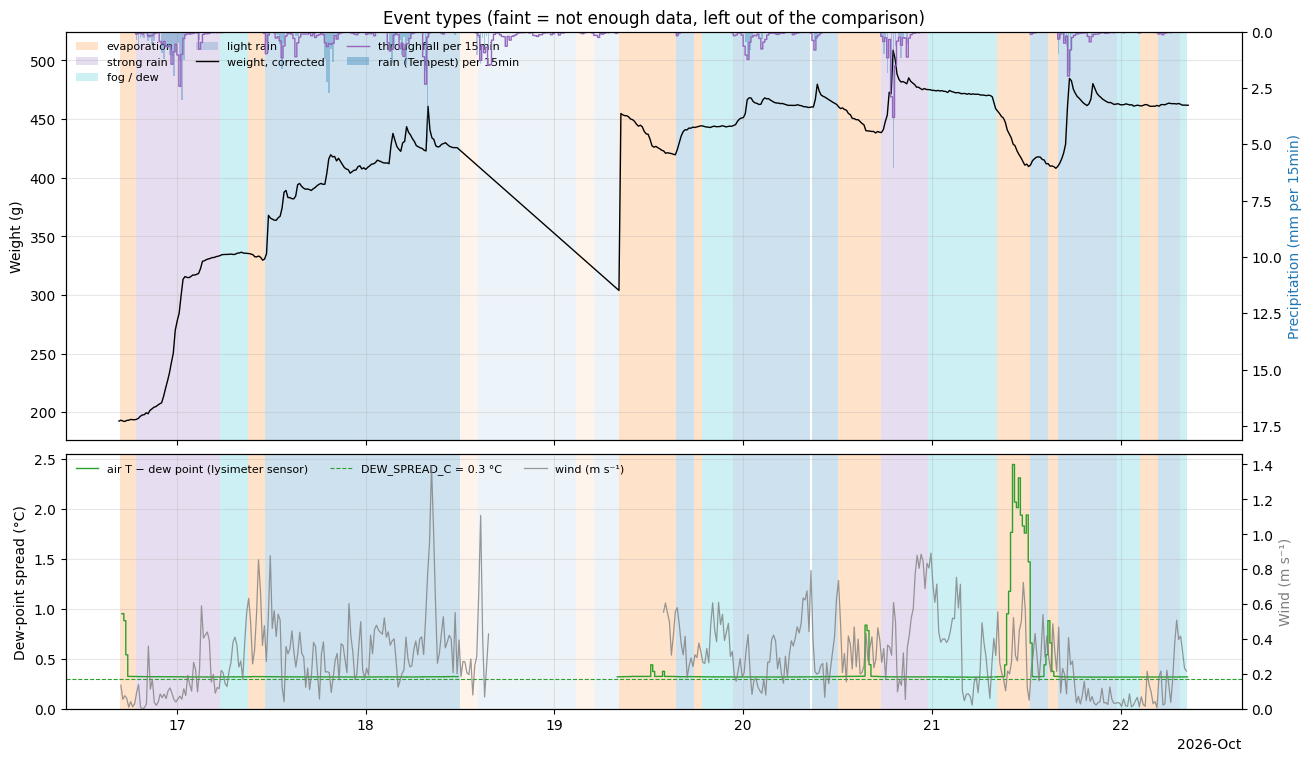

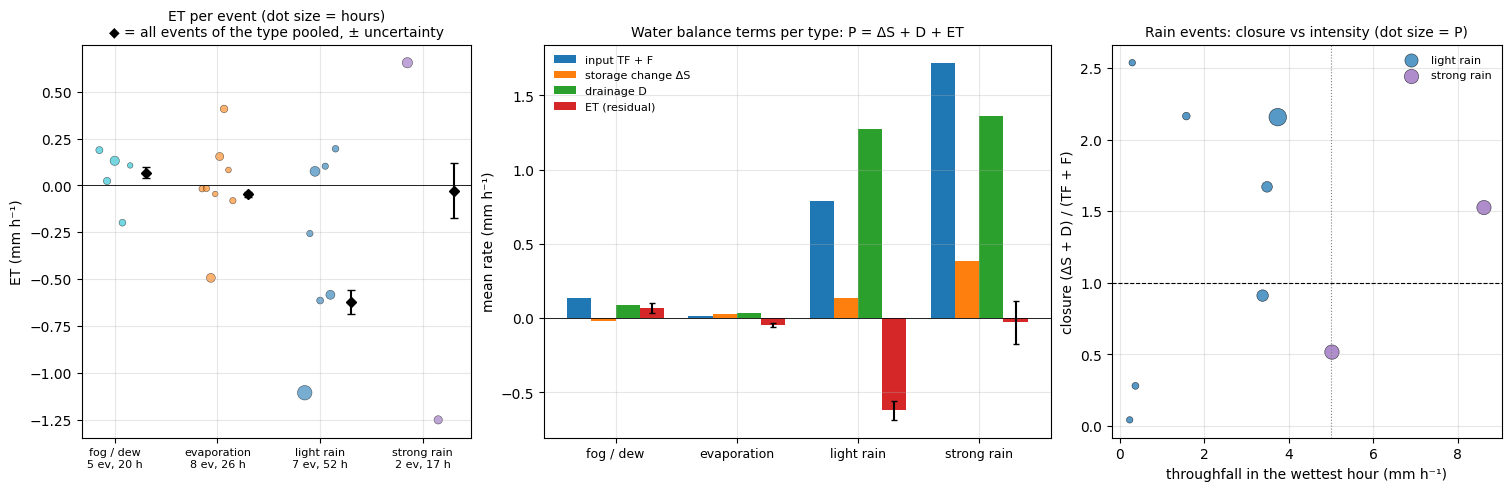

fog / dew   : 5 event(s), 19.8 h | ΔS -0.018, D 0.088, ET +0.068 ± 0.031 mm/h (+1.6 mm/d) | closure 0.51
evaporation : 8 event(s), 25.8 h | ΔS +0.029, D 0.033, ET -0.046 ± 0.013 mm/h (-1.1 mm/d)
light rain  : 7 event(s), 52.0 h | ΔS +0.133, D 1.276, ET -0.621 ± 0.064 mm/h (-14.9 mm/d) | closure 1.79
strong rain : 2 event(s), 16.8 h | ΔS +0.388, D 1.360, ET -0.028 ± 0.147 mm/h (-0.7 mm/d) | closure 1.02


In [18]:
# ---- Figures: event types over time, and how they compare ----
if type_ev.empty:
    print("⏭ Skipped event-type figures: no events")
else:
    # 1. Timeline: weight and inputs with the event types shaded; dew-point spread and wind underneath
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, constrained_layout=True,
                                   gridspec_kw={"height_ratios": [1.6, 1]})
    seen = set()
    for r in type_ev.itertuples():
        for a_ in (ax1, ax2):
            a_.axvspan(r.start, r.end, color=TYPE_COLORS[r.type], alpha=0.22 if r.used else 0.08, lw=0,
                       label=r.type if (a_ is ax1 and r.type not in seen) else None)
        seen.add(r.type)
    ax1.plot(dw["timestamp"], dw["weight_g"], color="k", lw=1, label="weight, corrected")
    ax1.set_ylabel("Weight (g)")
    ar = add_rain(ax1, offset=1.0)
    ax1.set_title("Event types (faint = not enough data, left out of the comparison)")
    legend_all(ax1, [ax1] + ([ar] if ar is not None else []), loc="upper left", ncol=3)
    ax2.step(wb["end"], wb["spread_C"], where="pre", color="tab:green", lw=1, label="air T − dew point (lysimeter sensor)")
    ax2.axhline(DEW_SPREAD_C, color="tab:green", ls="--", lw=0.8, label=f"DEW_SPREAD_C = {DEW_SPREAD_C} °C")
    ax2.set_ylabel("Dew-point spread (°C)")
    ax2.set_ylim(bottom=min(0, np.nanmin(wb["spread_C"])))
    axes2 = [ax2]
    if wb["wind_ms"].notna().any():
        tw2 = ax2.twinx(); tw2.grid(False)
        tw2.plot(wb["mid"], wb["wind_ms"], color="tab:grey", lw=0.9, alpha=0.8, label="wind (m s⁻¹)")
        tw2.set_ylabel("Wind (m s⁻¹)", color="tab:grey"); tw2.set_ylim(bottom=0)
        axes2.append(tw2)
    legend_all(ax2, axes2, loc="upper left", ncol=3)
    time_axis(ax2)
    finish(fig, "event_types_timeline")

if len(used_ev):
    present = [t_ for t_ in TYPES if t_ in type_tab.index]
    fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True,
                                        gridspec_kw={"width_ratios": [1, 1.3, 1]})
    # 2a. ET rate per event, with the pooled rate per type
    for i, t_ in enumerate(present):
        g = used_ev[used_ev["type"] == t_]
        jit = np.linspace(-0.15, 0.15, len(g)) if len(g) > 1 else np.zeros(1)
        axA.scatter(i + jit, g["ET_mmh"], s=12 + 4 * g["hours"], color=TYPE_COLORS[t_], alpha=0.6, edgecolor="k", lw=0.4)
        axA.errorbar(i + 0.3, type_tab.loc[t_, "ET_mmh"], yerr=type_tab.loc[t_, "±_mmh"], fmt="D", color="k", ms=5, capsize=3)
    axA.axhline(0, color="k", lw=0.6)
    axA.set_xticks(range(len(present)), [f"{t_}\n{int(type_tab.loc[t_, 'events'])} ev, {type_tab.loc[t_, 'hours']:.0f} h"
                                         for t_ in present], fontsize=8)
    axA.set_ylabel("ET (mm h⁻¹)")
    axA.set_title("ET per event (dot size = hours)\n◆ = all events of the type pooled, ± uncertainty", fontsize=10)

    # 2b. Mean rates of every balance term per type
    terms = [("P_mmh", "input TF + F", "tab:blue"), ("ΔS_mmh", "storage change ΔS", "tab:orange"),
             ("D_mmh", "drainage D", "tab:green"), ("ET_mmh", "ET (residual)", "tab:red")]
    x = np.arange(len(present)); wdt = 0.2
    for j, (c, lab, colr) in enumerate(terms):
        axB.bar(x + (j - 1.5) * wdt, type_tab.loc[present, c], wdt, color=colr, label=lab,
                yerr=type_tab.loc[present, "±_mmh"] if c == "ET_mmh" else None, capsize=2)
    axB.axhline(0, color="k", lw=0.6)
    axB.set_xticks(x, present, fontsize=9)
    axB.set_ylabel("mean rate (mm h⁻¹)")
    axB.legend(fontsize=8, frameon=False)
    axB.set_title("Water balance terms per type: P = ΔS + D + ET", fontsize=10)

    # 2c. Rain events: closure vs intensity of the wettest hour
    rv = used_ev[used_ev["type"].str.contains("rain") & used_ev["closure"].notna()]
    if len(rv):
        for t_ in ["light rain", "strong rain"]:
            g = rv[rv["type"] == t_]
            axC.scatter(g["peak_TF_mmh"], g["closure"], s=20 + 6 * g["P_mm"], color=TYPE_COLORS[t_], edgecolor="k",
                        lw=0.4, alpha=0.75, label=t_)
        axC.axhline(1, color="k", lw=0.8, ls="--")
        axC.axvline(STRONG_RAIN_MMH, color="grey", lw=0.8, ls=":")
        axC.set_xlabel("throughfall in the wettest hour (mm h⁻¹)")
        axC.set_ylabel("closure (ΔS + D) / (TF + F)")
        axC.legend(fontsize=8, frameon=False)
        axC.set_title("Rain events: closure vs intensity (dot size = P)", fontsize=10)
    else:
        axC.axis("off")
        axC.text(0.5, 0.5, "no rain events with enough data", ha="center", va="center")
    finish(fig, "event_types_comparison")

    # Plain-language summary
    for t_ in present:
        r = type_tab.loc[t_]
        line = (f"{t_:12s}: {int(r['events'])} event(s), {r['hours']:.1f} h | ΔS {r['ΔS_mmh']:+.3f}, D {r['D_mmh']:.3f}, "
                f"ET {r['ET_mmh']:+.3f} ± {r['±_mmh']:.3f} mm/h ({r['ET_mm_per_day']:+.1f} mm/d)")
        if pd.notna(r.get("closure", np.nan)):
            line += f" | closure {r['closure']:.2f}"
        print(line)